In [3]:
import os
import sys
import gzip
import json
import logging
import requests
import numpy as np
import pandas as pd
from io import BytesIO
from tqdm import tqdm
from astropy.table import Table
from astropy.io import fits
from astropy.coordinates import SkyCoord
import astropy.units as u
from desimodel.footprint import is_point_in_desi
from desispec.io import read_spectra
from desispec.coaddition import coadd_cameras
from desitrip.preproc import rebin_flux, rescale_flux
import psycopg2
import multiprocessing as mp
from astropy.coordinates import SkyCoord, match_coordinates_sky

In [2]:
import sys
import numpy as np

sys.path.insert(0, "/pscratch/sd/z/zixinq/timedomain/desitrip/py")

In [4]:
TNS_API_KEY = '006e7e40b06030997b93b0d0cf0973e56c408875'
TNS_BOT_NAME = 'DESIRT_Bot'
TNS_BOT_ID = 105220
CATALOG_URL = 'https://www.wis-tns.org/system/files/tns_public_objects/tns_public_objects.csv.zip'
DAILY_DIR = "/global/cfs/cdirs/desi/spectro/redux/daily"
TILE_ECSV = "/global/cfs/cdirs/desi/survey/ops/surveyops/trunk/ops/tiles-main.ecsv"

In [5]:
def download_tns_table():
    headers = {
        'user-agent': f'tns_marker{{"tns_id":"{TNS_BOT_ID}","type": "bot", "name":"{TNS_BOT_NAME}"}}'
    }
    data = {'api_key': (None, TNS_API_KEY)}
    r = requests.post(CATALOG_URL, headers=headers, data=data)
    return pd.read_csv(BytesIO(r.content), skiprows=1, compression='zip', low_memory=False)

In [6]:
tns_df = download_tns_table()
tns_df.to_csv("TNS_output.csv", index=False)

In [7]:
tns_df

,objid,name_prefix,name,ra,declination,redshift,typeid,type,reporting_groupid,reporting_group,...,discoverymag,discmagfilter,filter,reporters,time_received,internal_names,Discovery_ADS_bibcode,Class_ADS_bibcodes,creationdate,lastmodified
0,219922,AT,2026abhs,26.505678,-57.067546,NaN,NaN,NaN,59.0,GOTO,...,20.2700,120.0,L,"D. O'Neill, K. Ackley, M. Dyer, J. Lyman, K. U...",2026-09-11 22:23:50,GOTO26jkr,NaN,NaN,2026-09-11 22:23:53,2026-09-11 22:23:53
1,219921,AT,2026abhr,20.556745,-39.610687,NaN,NaN,NaN,59.0,GOTO,...,20.3100,120.0,L,"D. O'Neill, K. Ackley, M. Dyer, J. Lyman, K. U...",2026-09-11 22:22:57,GOTO26jks,NaN,NaN,2026-09-11 22:23:00,2026-09-11 22:23:00
2,219920,AT,2026abhq,34.609075,-6.924427,NaN,NaN,NaN,59.0,GOTO,...,19.9900,120.0,L,"D. O'Neill, K. Ackley, M. Dyer, J. Lyman, K. U...",2026-09-11 22:22:19,GOTO26jkv,NaN,NaN,2026-09-11 22:22:22,2026-09-11 22:22:22
3,219919,AT,2026abhp,28.027514,-57.821556,NaN,NaN,NaN,59.0,GOTO,...,20.3600,120.0,L,"D. O'Neill, K. Ackley, M. Dyer, J. Lyman, K. U...",2026-09-11 22:20:51,GOTO26jkq,NaN,NaN,2026-09-11 22:20:53,2026-09-11 22:20:53
4,219918,AT,2026abho,58.986962,-21.674310,NaN,NaN,NaN,59.0,GOTO,...,20.2500,120.0,L,"D. O'Neill, K. Ackley, M. Dyer, J. Lyman, K. U...",2026-09-11 22:20:05,GOTO26jku,NaN,NaN,2026-09-11 22:20:08,2026-09-11 22:20:08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
207230,10009,SN,2016H,154.819333,4.761667,0.046,3.0,SN Ia,4.0,Pan-STARRS,...,18.3486,26.0,w,Darryl Wright,2016-01-12 15:02:03,PS16fa,2016TNSTR..16....1W,2016TNSCR..18....1X,2016-01-12 15:02:03,2016-01-12 15:02:03
207231,10006,SN,2016E,75.933292,3.412472,0.055,3.0,SN Ia,4.0,Pan-STARRS,...,17.9573,22.0,r,Darryl Wright,2016-01-04 15:16:56,PS16n,2016TNSTR...6....1W,2016TNSCR..19....1Y,2016-01-04 15:16:56,2016-01-04 15:16:56
207232,10005,SN,2016D,60.358292,-54.758556,0.045,3.0,SN Ia,7.0,BOSS,...,16.5000,1.0,Clear,Stuart Parker,2016-01-04 12:41:07,NaN,2016TNSTR...5....1P,2016TNSCR..35....1A,2016-01-04 12:41:07,2016-01-04 12:41:07
207233,6309,SN,2013gj,40.291670,-21.024780,NaN,10.0,SN II,NaN,NaN,...,17.5000,NaN,NaN,A.J. Drake et al.,2021-02-17 11:24:00,NaN,2021TNSTR.496....1D,NaN,2015-12-31 10:59:55,2015-12-31 10:59:55


In [13]:
unique_values = tns_df['name'].unique()

len((unique_values))

174860

In [14]:
print(tns_df["type"].value_counts())

type
SN Ia                11524
SN II                 2791
FRB                   1024
CV                     592
SN IIn                 500
SN Ia-91T-like         453
SN Ic                  386
SN Ib                  313
SN IIP                 303
SN IIb                 272
SLSN-I                 198
SN Ic-BL               169
SN Ia-91bg-like        160
AGN                    150
Varstar                138
Nova                   125
SLSN-II                108
TDE                    106
SN Ia-pec               97
SN                      87
SN Ib/c                 79
SN Ibn                  69
Galaxy                  63
SN Iax[02cx-like]       59
SN I                    56
SN Ia-CSM               41
LBV                     22
M dwarf                 17
SN Ib-pec               17
SN II-pec               15
SN Ia-SC                15
QSO                     14
LRN                     14
SN Ib-Ca-rich           12
TDE-He                   9
SN Icn                   7
TDE-H-He               

In [8]:
def process_entry(args):
    idx, ra, dec, data_release, radius = args

    db = psycopg2.connect(host='decatdb.lbl.gov', database='desidb', user='desi', password='5kFibers!', port='5432')
    cursor = db.cursor()

    observed = "N"
    if np.isnan(ra) or np.isnan(dec):
        match = np.empty((11,))
        match[:] = np.nan
    else:
        query = f'''
        SELECT f.target_ra, f.target_dec, r.z, r.zerr, r.zwarn, r.spectype,
               f.tileid, f.petal_loc, f.targetid, f.fiber, c.night
        FROM {data_release}.tiles_fibermap f
        INNER JOIN {data_release}.cumulative_tiles c ON f.cumultile_id=c.id
        INNER JOIN {data_release}.tiles_redshifts r ON r.cumultile_id=c.id AND r.targetid=f.targetid
        WHERE q3c_radial_query(f.target_ra, f.target_dec, {ra}, {dec}, {radius});
        '''

        cursor.execute(query)
        targets = cursor.fetchall()

        if len(targets) >= 1:
            targets = np.array(targets)
            zwarn = '1'

            while zwarn != '0' and len(targets) > 0:
                ra_lst, dec_lst = targets[:, 0].astype(float).tolist(), targets[:, 1].astype(float).tolist()
                match_idx = match_coordinates_sky(SkyCoord(ra * u.deg, dec * u.deg),
                                                  SkyCoord(ra_lst * u.deg, dec_lst * u.deg),
                                                  nthneighbor=1)[0]
                match = targets[match_idx]
                zwarn = match[4]
                if zwarn != '0':
                    targets = np.delete(targets, match_idx, 0)

        if len(targets) == 0:
            match = np.empty((11,))
            match[:] = np.nan
        else:
            observed = "Y"

    cursor.close()
    db.close()

    return idx, match[2], match[3], match[5], observed, match[6], match[7], match[8], match[9], match[10]

In [9]:
def crossmatch_catalog(catalog_df, data_release='daily', radius_arcsec=1.6, cores=16,
                       ra_col='RA', dec_col='DEC', save_to=None, filter_spectype=None):
    
    radius_deg = radius_arcsec / 3600.0

    args_list = [
        (idx, float(ra), float(dec), data_release, radius_deg)
        for idx, (ra, dec) in enumerate(zip(catalog_df[ra_col], catalog_df[dec_col]))
    ]

    with mp.Pool(processes=cores) as pool:
        results = list(tqdm(pool.imap(process_entry, args_list), total=len(args_list)))

    cols = {
        "Z": [], "Z_ERR": [], "SPECTYPE": [], "OBSERVATION_STATUS": [],
        "TILEID": [], "PETAL_LOC": [], "TARGETID": [], "FIBER": [], "NIGHT": []
    }
    for _, z, zerr, spectype, observed, tileid, petal_loc, targetid, fiber, night in results:
        cols["Z"].append(z)
        cols["Z_ERR"].append(zerr)
        cols["SPECTYPE"].append(spectype)
        cols["OBSERVATION_STATUS"].append(observed)
        cols["TILEID"].append(tileid)
        cols["PETAL_LOC"].append(petal_loc)
        cols["TARGETID"].append(targetid)
        cols["FIBER"].append(fiber)
        cols["NIGHT"].append(night)

    for key, values in cols.items():
        catalog_df[key] = values

    n_match = catalog_df["Z"].notnull().sum()
    print(f"{n_match} out of {len(catalog_df)} objects have a DESI redshift.")

    if filter_spectype:
        catalog_df = catalog_df[catalog_df["SPECTYPE"] == filter_spectype]
        print(f"Filtered to {len(catalog_df)} entries with SPECTYPE == '{filter_spectype}'.")

    # Save output
    if save_to:
        if save_to == 'scratch':
            save_path = os.path.join(os.environ['PSCRATCH'], 'crossmatch_results.csv')
        else:
            save_path = save_to
        catalog_df.to_csv(save_path, index=False)
        print(f"Saved crossmatched catalog to: {save_path}")

    return catalog_df


In [8]:
tns_matched_df = crossmatch_catalog(
    catalog_df=tns_df,                     
    data_release='daily',                 
    radius_arcsec=1.6,                   
    cores=12,
    ra_col='ra',
    dec_col='declination',
    filter_spectype=None                  
)

100%|██████████| 172655/172655 [07:52<00:00, 365.76it/s]


29937 out of 172655 objects have a DESI redshift.


In [9]:
tns_matched_only = tns_matched_df[tns_matched_df["OBSERVATION_STATUS"] == "Y"]

In [10]:
#save crossmatched df
output_dir = "/global/cfs/cdirs/m4237/zixinq/data"
csv_path = os.path.join(output_dir, "tns_matched.csv")
tns_matched_only.to_csv(csv_path, index=False)
print(f"Saved to {csv_path}")

Saved to /global/cfs/cdirs/m4237/zixinq/data/tns_matched.csv


In [74]:
import pandas as pd

tns_path = "/global/cfs/cdirs/m4237/zixinq/data/tns_matched.csv"
tns_df = pd.read_csv(tns_path)

In [24]:
tns_df = tns_df[tns_df['type'].notna() & (tns_df['type'] != '')]

In [26]:
#save crossmatched df
output_dir = "/global/cfs/cdirs/m4237/zixinq/data"
csv_path = os.path.join(output_dir, "tns_matched.csv")
tns_df.to_csv(csv_path, index=False)
print(f"Saved to {csv_path}")

Saved to /global/cfs/cdirs/m4237/zixinq/data/tns_matched.csv


In [31]:
print(tns_df["type"].value_counts())

type
SN Ia                1932
SN II                 316
SN Ia-91T-like         79
SN IIn                 71
TDE                    62
SN Ic                  59
AGN                    57
SN Ib                  42
SN Ic-BL               31
SN IIb                 31
SN IIP                 31
Galaxy                 25
CV                     24
SLSN-II                24
SN Ia-pec              17
SLSN-I                 17
SN I                   12
SN Ibn                 10
SN                      9
SN Ib/c                 8
SN Ia-CSM               8
QSO                     7
TDE-He                  7
SN Ia-91bg-like         6
TDE-H-He                5
SN Iax[02cx-like]       4
Varstar                 4
FRB                     2
TDE-featureless         2
M dwarf                 2
Nova                    2
LBV                     2
Blazar                  1
Impostor-SN             1
SN II-pec               1
SN IIL                  1
SN Ib-pec               1
Name: count, dtype: int64


In [75]:
tns_df

,objid,name_prefix,name,ra,declination,redshift,typeid,type,reporting_groupid,reporting_group,...,lastmodified,Z,Z_ERR,SPECTYPE,OBSERVATION_STATUS,TILEID,PETAL_LOC,TARGETID,FIBER,NIGHT
0,184894,SN,2025shi,342.176185,27.582791,0.031952,9.0,SN Ibn,74.0,ALeRCE,...,2025-09-07 17:48:55,1.277715,2.084523e-04,GALAXY,Y,43924,2,43978098106275584,1300,20250808
1,188096,SN,2025wxi,255.533916,60.963317,0.065759,3.0,SN Ia,139.0,LAST,...,2025-09-07 08:42:11,0.065784,1.933581e-05,GALAXY,Y,23886,6,39633399643637216,3463,20230513
2,188089,SN,2025wxb,226.430007,19.732737,0.074260,3.0,SN Ia,18.0,ATLAS,...,2025-09-07 08:40:27,0.074319,3.438935e-05,GALAXY,Y,23343,2,39628256722289446,1386,20230507
3,186903,SN,2025vfk,239.537911,48.194083,0.083000,3.0,SN Ia,18.0,ATLAS,...,2025-09-06 06:03:07,0.071139,6.072358e-06,GALAXY,Y,25432,3,39633220966285777,1795,20230502
4,185696,SN,2025tlc,245.838212,8.920889,0.049000,3.0,SN Ia,18.0,ATLAS,...,2025-09-05 11:46:33,0.048795,1.394074e-05,GALAXY,Y,21988,3,39628005542201864,1955,20220430
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2908,10040,SN,2015bk,105.869259,58.217186,0.249000,3.0,SN Ia,2.0,iPTF,...,2016-01-27 12:51:58,0.248350,5.649568e-06,GALAXY,Y,6693,9,39633364604420558,4884,20241030
2909,10032,SN,2016ad,139.169708,22.298000,0.050000,3.0,SN Ia,4.0,Pan-STARRS,...,2016-01-21 17:19:38,0.050392,5.005152e-06,GALAXY,Y,26091,5,39628311822862858,2535,20231217
2910,10019,SN,2016Q,122.582750,19.446722,0.103000,9.0,SN Ibn,4.0,Pan-STARRS,...,2016-01-19 17:18:38,0.103485,4.778659e-06,GALAXY,Y,26050,9,39628249378062937,4743,20221009
2911,10018,SN,2016P,209.379583,6.097500,0.014600,7.0,SN Ic-BL,12.0,RANSSP,...,2016-01-19 16:38:47,0.014408,8.411516e-07,GALAXY,Y,148,4,39627933022683409,2234,20210407


In [3]:
#match with classified transients from google sheets
classified_new = pd.read_csv("desi_spectra.csv", dtype=str)
classified_old = pd.read_csv("prelim_final_table - prelim_final_table_all.csv", dtype=str)

classified_old_subset = classified_old.rename(columns={'type': 'TYPE'})[
    ['TARGETID', 'NIGHT', 'RA', 'DEC', 'TYPE', 'Z', 'obsdate', 'discoverydate']
]
classified_new_subset = classified_new[['TARGETID', 'NIGHT', 'RA', 'DEC', 'TYPE']].copy()
classified_new_subset['Z'] = None
classified_new_subset['obsdate'] = None
classified_new_subset['discoverydate'] = None

classified_all = pd.concat([classified_old, classified_new], ignore_index=True)
classified_all = classified_all.drop_duplicates(subset=["TARGETID"])

In [14]:
classified_all = pd.read_csv("classified_all.csv", dtype=str)

In [15]:
classified_all

,TARGETID,NIGHT,RA,DEC,TYPE,Z,obsdate,discoverydate
0,39628163621326262,20230226,167.4989834,15.75684285,TDE,0.1848671123,2023-02-26,2023-01-13 10:56:38
1,39628391070046419,20220610,262.460454,25.84218305,TDE,0.09538679395,2022-06-10,2022-03-20 14:41:18
2,39633493369555948,20220113,104.6236803,70.56078803,TDE,0.08098867152,2022-01-13,2022-01-21 7:17:46
3,39633240285251637,20220318,185.1877349,49.5512831,TDE,0.02843634506,2022-03-18,2022-02-22 14:52:48
4,39632976878768365,20210416,252.5306153,34.81883132,TDE,0.3578223547,2021-04-16,2021-03-18 11:44:34
...,...,...,...,...,...,...,...,...
380,43977510576550849,20250502,208.095423,2.345902,NaN,NaN,NaN,NaN
381,43977522635174890,20250502,206.932347,2.638603,NaN,NaN,NaN,NaN
382,43977534718964759,20250502,207.416154,3.205182,NaN,NaN,NaN,NaN
383,43977546790171838,20250502,207.819776,3.752963,NaN,NaN,NaN,NaN


In [48]:
classified = pd.read_csv("onqueue_classifications.csv", dtype = str)
classified_new = pd.read_csv("dts_classifications - dts_classifications_snr5.csv", dtype = str)
classified_subset = classified.rename(
    columns={
        'CHOSEN_CLASS': 'TYPE',
        'RR_Z': 'Z',
        'DISCOVERY_DATE': 'discoverydate',
        'OBS_ISO': 'obsdate'
    }
)[
    [
        'TARGETID',
        'TILEID',
        'PETAL_LOC',
        'NIGHT',
        'RA',
        'DEC',
        'TYPE',
        'Z',
        'obsdate',
        'discoverydate'
    ]
]
classified_new_subset = classified_new.rename(
    columns={
        'CHOSEN_CLASS': 'TYPE',
        'RR_Z': 'Z',
        'DISCOVERY_DATE': 'discoverydate',
        'OBS_ISO': 'obsdate'
    }
)[
    [
        'TARGETID',
        'TILEID',
        'PETAL_LOC',
        'NIGHT',
        'RA',
        'DEC',
        'TYPE',
        'Z',
        'obsdate',
        'discoverydate'
    ]
]

'''
classified_new_subset['Z'] = None
classified_new_subset['obsdate'] = None
classified_new_subset['discoverydate'] = None
'''

classified_all = pd.concat([classified_subset, classified_new_subset], ignore_index=True)

In [38]:
print(classified_new_subset[["TARGETID", "NIGHT", "RA", "DEC"]].head(20))

for col in ["TARGETID", "NIGHT", "RA", "DEC"]:
    print("\n", col)
    print(classified_new_subset[col].head(10).map(repr).to_list())

             TARGETID     NIGHT          RA         DEC
0   43976839345350764  20260801   311.23578  -26.617425
1   43976906546456147  20250924   39.343517  -23.344875
2   43976912598838152  20251111   71.014711  -22.876483
3   43976912615614745  20251111   72.083832  -23.099821
4   43976912674335833  20251028   75.682211  -23.011634
5   43976912674335833  20251031   75.682211  -23.011634
6   43976916180805199  20260802  302.329307  -23.068663
7   43976918173072101  20251221   70.926933  -22.815323
8   43976928642053904  20251213   26.026379  -22.162676
9   43976928642053904  20251220   26.026379  -22.162676
10  43976929384444177  20251113   73.905547  -22.347158
11  43976934853816422  20251129   65.589791  -21.888575
12  43976934853816422  20251205   65.589791  -21.888575
13  43976935105477339  20251220   81.674138  -22.082978
14  43976945540901495  20251107   30.324649  -21.588101
15  43976945540901495  20251109   30.324649  -21.588101
16  43976945909999325  20251002   53.951931  -21

In [27]:
classified_all

,TARGETID,NIGHT,RA,DEC,TYPE,Z,obsdate,discoverydate
0,2389938691637248,NaN,173.3231798,17.282333,Ia,0.06141697047,2024-03-04 7:22:32,2024-02-14 9:26:54
1,2390419019137026,NaN,178.5553043,39.90443005,Ib/c?,0.05719667296,2025-01-20 10:54:25,2024-12-19 16:10:20
2,2707083182997506,NaN,192.8293283,40.20148036,II,0.06556503895,2025-03-22 7:39:49,2025-02-28 9:47:43
3,2842079726141446,NaN,78.64162381,-18.74740572,Ia,0.0535719711,2025-10-20 11:50:41,2025-10-09 12:27:16
4,2842241315897344,NaN,339.7073762,-11.98045008,host,0.1367791493,2024-09-22 22:00:29,2024-09-25 5:36:21
...,...,...,...,...,...,...,...,...
1135,43978791550574289,20260414,212.205708,74.302798,host,0.03726985415,2026-04-15 6:22:33,2026-03-23 10:02:33
1136,43978798131431675,20260227,254.319902,75.130528,qso,0.2561017004,2026-02-28 12:43:24,2026-02-02 10:05:19
1137,43978798131431675,20260311,254.319902,75.130528,qso,0.258533103,2026-03-12 10:13:56,2026-02-02 10:05:19
1138,43978799456837418,20260324,205.037583,75.386257,host,0.1322345385,2026-03-25 6:26:41,2026-03-24 10:02:56


In [40]:
tr = np.load("/global/cfs/cdirs/m4237/zixinq/data/transient_coadd_fluxes_classified.npz", allow_pickle=True)

In [41]:
targetid_npz = tr["TARGETID"]   # shape (N,)

In [44]:
df = classified_all[["TARGETID", "Z", "TYPE"]].copy()

In [46]:
targetid_npz = tr["TARGETID"]   # shape (N,)

# 2. Take only the columns we need from classified_all
df_meta = classified_all[["TARGETID", "Z", "TYPE"]].copy()

# 3. Drop rows with missing TARGETID (they can't match anyway)
df_meta = df_meta.dropna(subset=["TARGETID"]).copy()

# 4. Make sure both sides use the SAME dtype (float is easiest)
df_meta["TARGETID"] = df_meta["TARGETID"].astype(float)
df_npz = pd.DataFrame({"TARGETID": targetid_npz.astype(float)})

# 5. Merge in the same order as targetid_npz
merged = df_npz.merge(df_meta, on="TARGETID", how="left")

# 6. Extract aligned arrays
z_arr    = merged["Z"].to_numpy()
type_arr = merged["TYPE"].astype(object).to_numpy()   # keep as strings

In [49]:
unknown = type_arr == "nan"
print("Missing type:", unknown.sum())

Missing type: 0


In [51]:
fields = {key: tr[key] for key in tr.files if key != "TYPE"}

np.savez(
    "/global/cfs/cdirs/m4237/zixinq/data/transient_coadd_fluxes_classified.npz",
    **fields,
    TYPE=type_arr,      # your new type array
)


In [3]:
classified_new

,TARGETID,NIGHT,RA,DEC,TYPE,Z,obsdate,discoverydate
0,43978027423847868,20241203,343.23789,24.281388,Ia-91T,None,None,None
1,43978111561586109,20241203,168.526832,28.139787,Ia-norm,None,None,None
2,43977036716660246,20241204,30.755192,-17.604831,Ia-91bg?,None,None,None
3,43977290522384112,20241205,34.986606,-6.864954,blank,None,None,None
4,43977260570859559,20241205,36.445519,-7.998088,IIn,None,None,None
...,...,...,...,...,...,...,...,...
192,43977546777588662,20250502,207.056018,3.744032,NaN,None,None,None
193,43977510576550849,20250502,208.095423,2.345902,NaN,None,None,None
194,43977522635174890,20250502,206.932347,2.638603,NaN,None,None,None
195,43977534718964759,20250502,207.416154,3.205182,NaN,None,None,None


In [4]:
classified_old

,TARGETID,NIGHT,RA,DEC,TYPE,Z,obsdate,discoverydate
0,39628163621326262,20230226,167.4989834,15.75684285,TDE,0.1848671123,2023-02-26,2023-01-13 10:56:38
1,39628391070046419,20220610,262.460454,25.84218305,TDE,0.09538679395,2022-06-10,2022-03-20 14:41:18
2,39633493369555948,20220113,104.6236803,70.56078803,TDE,0.08098867152,2022-01-13,2022-01-21 7:17:46
3,39633240285251637,20220318,185.1877349,49.5512831,TDE,0.02843634506,2022-03-18,2022-02-22 14:52:48
4,39632976878768365,20210416,252.5306153,34.81883132,TDE,0.3578223547,2021-04-16,2021-03-18 11:44:34
...,...,...,...,...,...,...,...,...
193,39628098542503109,20211021,127.994444,13.02928202,Ia,0.1037540009,2021-10-21,2021-10-09 10:57:00
194,39627609918670345,20211020,358.5710362,-7.442150961,Ia,0.1260714493,2021-10-20,2021-10-01 6:56:28
195,39628007748405596,20211015,18.87789028,9.331050277,Ia,0.08599287924,2021-10-15,2021-10-01 7:59:02
196,39627444793115354,20211026,61.56970441,-14.29852968,Ia,0.1535108439,2021-10-26,2021-10-01 9:36:12


In [5]:
classified_all.to_csv("classified_all.csv", index=False)

In [6]:
classified_all

,TARGETID,NIGHT,RA,DEC,TYPE,Z,obsdate,discoverydate
0,39628163621326262,20230226,167.4989834,15.75684285,TDE,0.1848671123,2023-02-26,2023-01-13 10:56:38
1,39628391070046419,20220610,262.460454,25.84218305,TDE,0.09538679395,2022-06-10,2022-03-20 14:41:18
2,39633493369555948,20220113,104.6236803,70.56078803,TDE,0.08098867152,2022-01-13,2022-01-21 7:17:46
3,39633240285251637,20220318,185.1877349,49.5512831,TDE,0.02843634506,2022-03-18,2022-02-22 14:52:48
4,39632976878768365,20210416,252.5306153,34.81883132,TDE,0.3578223547,2021-04-16,2021-03-18 11:44:34
...,...,...,...,...,...,...,...,...
390,43977546777588662,20250502,207.056018,3.744032,NaN,None,None,None
391,43977510576550849,20250502,208.095423,2.345902,NaN,None,None,None
392,43977522635174890,20250502,206.932347,2.638603,NaN,None,None,None
393,43977534718964759,20250502,207.416154,3.205182,NaN,None,None,None


In [99]:
#match tns catalog with classified transients
tns_df["TARGETID"] = pd.to_numeric(tns_df["TARGETID"], errors="coerce")
classified_all["TARGETID"] = pd.to_numeric(classified_all["TARGETID"], errors="coerce")

tns_df = tns_df.dropna(subset=["TARGETID"])
classified_all = classified_all.dropna(subset=["TARGETID"])

tns_df["TARGETID"] = tns_df["TARGETID"].astype(int)
classified_all["TARGETID"] = classified_all["TARGETID"].astype(int)

import pandas as pd

merged = pd.merge(
    classified_all,
    tns_df,
    on="TARGETID",
    how="outer", 
    suffixes=("_desi", "_tns")
)
print(f"{len(merged)} TNS-classified transients matched to DESI spectra")

output_dir = "/global/cfs/cdirs/m4237/zixinq/data"
csv_path = os.path.join(output_dir, "matched_classified_transients.csv")
merged.to_csv(csv_path, index=False)

print(f"{len(merged)} classified TNS transients matched to DESI spectra")
print(f"Saved to: {csv_path}")

3184 TNS-classified transients matched to DESI spectra
3184 classified TNS transients matched to DESI spectra
Saved to: /global/cfs/cdirs/m4237/zixinq/data/matched_classified_transients.csv


In [82]:
merged["type"] = merged["type"].combine_first(merged["TYPE"])

In [41]:
merged['Z'] = merged['Z_x'].combine_first(merged['Z_y'])
merged['NIGHT'] = merged['NIGHT_x'].combine_first(merged['NIGHT_y'])
merged['discoverydate'] = merged['discoverydate_x'].combine_first(merged['discoverydate_y'])

merged = merged.drop(columns=[
    'Z_x', 'Z_y',
    'NIGHT_x', 'NIGHT_y',
    'discoverydate_x', 'discoverydate_y'
])

In [46]:
print(merged.columns.tolist())

['TARGETID', 'NIGHT_desi', 'RA', 'DEC', 'TYPE', 'Z_desi', 'obsdate', 'discoverydate_desi', 'objid', 'name_prefix', 'name', 'ra', 'declination', 'redshift', 'typeid', 'type', 'reporting_groupid', 'reporting_group', 'source_groupid', 'source_group', 'discoverydate_tns', 'discoverymag', 'discmagfilter', 'filter', 'reporters', 'time_received', 'internal_names', 'Discovery_ADS_bibcode', 'Class_ADS_bibcodes', 'creationdate', 'lastmodified', 'Z_tns', 'Z_ERR', 'SPECTYPE', 'OBSERVATION_STATUS', 'TILEID', 'PETAL_LOC', 'FIBER', 'NIGHT_tns']


In [54]:
print(merged["TYPE"].value_counts())

TYPE
Ia          153
II           36
Ia-norm      30
Host         16
Gal           6
Ib/c          6
TDE           6
AGN?          6
GWGal         6
AGN           6
Ia-CSM?       5
II-norm       5
IIn           4
???           4
Gal?          4
Quasar        4
II?           3
bad           3
Star          2
blank         2
IIn?          2
Blank         1
Ib-norm       1
Ia-91T        1
QSO           1
QSO/TDE?      1
GWAGN         1
Star?         1
Flat          1
Ibn/TDE?      1
bad?          1
QSO?          1
Ia-pec        1
Ia-91bg?      1
Host?         1
Ic-pec        1
Name: count, dtype: int64


In [7]:
print(classified_all["TYPE"].value_counts())

TYPE
Ia          153
II           36
Ia-norm      30
Host         16
GWGal         6
AGN?          6
AGN           6
TDE           6
Gal           6
Ib/c          6
Ia-CSM?       5
II-norm       5
Quasar        4
???           4
IIn           4
Gal?          4
bad           3
II?           3
blank         2
IIn?          2
Star          2
bad?          1
Blank         1
GWAGN         1
QSO           1
QSO?          1
Host?         1
Flat          1
Star?         1
Ibn/TDE?      1
Ic-pec        1
Ia-pec        1
Ib-norm       1
Ia-91bg?      1
Ia-91T        1
QSO/TDE?      1
Name: count, dtype: int64


In [100]:
import pandas as pd
import numpy as np

def coalesce_cols(df):
    out = df.copy()

    # provenance flags if present from an outer merge
    if "_merge" in out.columns:
        out["from_desi"] = out["_merge"].isin(["left_only","both"])
        out["from_tns"]  = out["_merge"].isin(["right_only","both"])
        out.drop(columns="_merge", inplace=True)

    # --- helpers ---
    to_num = lambda s: pd.to_numeric(s, errors="coerce")
    to_dt  = lambda s: pd.to_datetime(s, errors="coerce")

    # --- numeric coercion for coords & redshifts on BOTH sides ---
    # DESI side (may already be numeric, safe to re-coerce)
    if "RA" in out:  out["RA_desi_num"]  = to_num(out["RA"])
    if "DEC" in out: out["DEC_desi_num"] = to_num(out["DEC"])
    if "Z_desi" in out: out["Z_desi_num"] = to_num(out["Z_desi"])

    # TNS side
    if "ra" in out:           out["ra_tns_num"]  = to_num(out["ra"])
    if "declination" in out:  out["dec_tns_num"] = to_num(out["declination"])
    if "Z_tns" in out:        out["Z_tns_num"]   = to_num(out["Z_tns"])
    if "redshift" in out:     out["redshift_num"]= to_num(out["redshift"])

    # --- unify coordinates: prefer DESI, fallback to TNS ---
    out["RA_unified"]  = out.get("RA_desi_num").combine_first(out.get("ra_tns_num"))
    out["DEC_unified"] = out.get("DEC_desi_num").combine_first(out.get("dec_tns_num"))
    out["type_unified"] = out.get("type").combine_first(out.get("TYPE"))

    # --- unify redshift: prefer DESI, then TNS (Z_tns), then TNS redshift ---
    z_candidates = [out.get("Z_desi_num"), out.get("Z_tns_num"), out.get("redshift_num")]
    z_unified = None
    for zc in z_candidates:
        z_unified = zc if z_unified is None else z_unified.combine_first(zc)
    out["Z_unified"] = z_unified

    # dates
    if "discoverydate_tns" in out or "discoverydate_desi" in out:
        out["discoverydate"] = out.get("discoverydate_tns").combine_first(out.get("discoverydate_desi"))
        out["discoverydate"] = to_dt(out["discoverydate"])
    if "obsdate" in out:
        out["obsdate"] = to_dt(out["obsdate"])

    # canonical NIGHT (prefer DESI)
    out["NIGHT"] = out.get("NIGHT_desi").combine_first(out.get("NIGHT_tns"))

    # derived: days since discovery (if both available)
    if {"obsdate","discoverydate"} <= set(out.columns):
        out["DAYS_SINCE_DISC"] = (out["obsdate"] - out["discoverydate"]).dt.days

    # --- optional: quick sep estimate (arcsec), only where both numeric exist ---
    if {"RA_desi_num","ra_tns_num","DEC_desi_num","dec_tns_num"} <= set(out.columns):
        # mask rows where all needed values are finite
        m = (
            out["RA_desi_num"].notna() &
            out["ra_tns_num"].notna() &
            out["DEC_desi_num"].notna() &
            out["dec_tns_num"].notna()
        )
        sep = pd.Series(np.nan, index=out.index, dtype=float)
        if m.any():
            dra = (out.loc[m,"RA_desi_num"] - out.loc[m,"ra_tns_num"]) * \
                  np.cos(np.deg2rad(out.loc[m,"DEC_desi_num"]))
            ddec = out.loc[m,"DEC_desi_num"] - out.loc[m,"dec_tns_num"]
            sep.loc[m] = np.sqrt(dra**2 + ddec**2) * 3600.0  # arcsec
        out["SEP_ARCSEC_APPROX"] = sep

    # tidy names (rename unified to canonical)
    out.drop(columns=[c for c in ["RA", "DEC","Z","TYPE"] if c in out.columns], inplace=True, errors="ignore")
    out = out.rename(columns={
        "RA_unified": "RA",
        "DEC_unified": "DEC",
        "Z_unified": "Z",
        "type_unified": "TYPE"
    })

    # optional: drop helper numeric columns
    drop_helpers = [
        "RA_desi_num","DEC_desi_num","ra_tns_num","dec_tns_num",
        "Z_desi_num","Z_tns_num","redshift_num"
    ]
    out.drop(columns=[c for c in drop_helpers if c in out.columns], inplace=True, errors="ignore")

    # nice column order (keep if present)
    cols_order = [
        "TARGETID","NIGHT",
        "RA","DEC","Z","redshift","Z_ERR",
        "TYPE","typeid","SPECTYPE","OBSERVATION_STATUS",
        "obsdate","discoverydate","DAYS_SINCE_DISC",
        "TILEID","PETAL_LOC","FIBER",
        "name_prefix","name","objid",
        "reporting_groupid","reporting_group","source_groupid","source_group",
        "discoverydate_tns","discoverymag","discmagfilter","filter",
        "reporters","time_received","internal_names",
        "Discovery_ADS_bibcode","Class_ADS_bibcodes",
        "creationdate","lastmodified",
        "SEP_ARCSEC_APPROX"
    ]
    cols_order = [c for c in cols_order if c in out.columns]
    out = out[cols_order]

    return out


# Usage
# merged is your outer-merged dataframe with suffixes applied earlier
clean = coalesce_cols(merged)


In [101]:
clean

,TARGETID,NIGHT,RA,DEC,Z,redshift,Z_ERR,TYPE,typeid,SPECTYPE,...,discmagfilter,filter,reporters,time_received,internal_names,Discovery_ADS_bibcode,Class_ADS_bibcodes,creationdate,lastmodified,SEP_ARCSEC_APPROX
0,2323290886504448,20221219.0,57.526167,-11.003411,0.129543,0.130000,8.281214e-06,SLSN-II,19.0,GALAXY,...,110.0,g,C. Fremling (Caltech) on behalf of the Zwicky ...,2018-11-02 00:33:48,"ZTF18acbvhfl, ATLAS18yfd, PS18crl, Gaia19alq",2018TNSTR1674....1F,"2018TNSCR1877....1F, 2020TNSCR1667....1D",2018-11-02 00:33:49,2018-11-02 00:33:49,NaN
1,2324485126488065,20250430.0,197.006969,42.013624,0.120858,0.121000,3.751805e-06,SN Ia,3.0,GALAXY,...,111.0,r,"J. Nordin, V. Brinnel, M. Giomi, J. van Santen...",2019-01-11 14:20:10,ZTF19aaafgbt,2019TNSTR..74....1N,2019TNSCR..97....1P,2019-01-11 14:20:11,2019-01-11 14:20:11,NaN
2,2324739821404172,20250330.0,172.134987,58.562244,0.010484,0.010300,4.373368e-06,SN IIb,14.0,GALAXY,...,NaN,NaN,"E. Kankare, P. Charalampopoulos, R. Kotak, K. ...",2024-04-21 08:11:26,ZTF19abgbbzy,2024TNSTR1159....1K,2024TNSCR1169....1K,2024-04-21 08:32:48,2024-04-21 09:07:43,NaN
3,2389120617807872,20241210.0,40.725792,-17.002985,0.029046,0.020000,2.721487e-05,SN Ia,3.0,GALAXY,...,71.0,cyan,"J. Tonry, L. Denneau, A. Heinze, H. Weiland (I...",2020-12-15 12:08:24,"ATLAS20bihi, PS21bt",2020TNSTR3793....1T,"2020TNSCR3811....1P, 2020TNSCR3837....1D",2020-12-15 12:08:24,2021-01-07 00:31:33,NaN
4,2389533672865796,20220307.0,161.805375,0.203811,0.037761,0.035000,7.614206e-06,SN Ia,3.0,GALAXY,...,71.0,cyan,"J. Tonry, B. Stalder, L. Denneau, A. Heinze, H...",2017-12-06 13:39:03,"ATLAS17nmr, PS17gab, Gaia18aau",2017TNSTR1376....1T,2017TNSCR1407....1A,2017-12-06 13:39:04,2017-12-06 13:39:04,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3179,2305843047297982627,20211218.0,53.308166,-14.676496,0.088767,0.090000,1.621469e-05,SN Ia,3.0,GALAXY,...,111.0,r,"F. Forster, F.E. Bauer, A. Munoz-Arancibia, L....",2020-10-28 20:36:53,ZTF20acmntog,2020TNSTR3277....1F,2020TNSCR3306....1I,2020-10-28 20:36:55,2020-11-03 07:58:43,NaN
3180,2305843047482525537,20241112.0,31.137045,-21.119312,0.016669,0.017000,4.332165e-07,SN II,10.0,GALAXY,...,111.0,r,"J. Nordin, V. Brinnel, J. van Santen (HU Berli...",2021-11-03 07:34:52,"ZTF20ackzfvn, ATLAS21blvp, PS21ojv",2021TNSTR3742....1N,2021TNSCR4027....1R,2021-11-03 07:34:53,2021-12-31 20:22:33,NaN
3181,2305843047532855891,20240105.0,33.472202,-18.158156,0.059822,0.059805,2.248597e-05,SN Ia,3.0,GALAXY,...,110.0,g,"J. Nordin, V. Brinnel, J. van Santen (HU Berli...",2021-09-19 10:40:36,ZTF18abxhaop,2021TNSTR3237....1N,2021TNSCR3263....1C,2021-09-19 10:40:37,2021-09-21 23:36:26,NaN
3182,2305843047843238321,20230830.0,41.040420,-4.718486,-0.000025,0.000000,3.005857e-06,M dwarf,210.0,STAR,...,110.0,g,"F. Forster, F.E. Bauer, G. Pignata, A. Munoz-A...",2022-09-18 18:56:02,ZTF22abggvny,2022TNSTR2682....1F,2022TNSCR3008....1J,2022-09-18 18:56:08,2024-02-28 00:05:03,NaN


In [102]:
clean["TYPE"] = clean["TYPE"].apply(simplify_label)

In [103]:
print(clean["TYPE"].value_counts())

TYPE
SN Ia      2160
SN II       472
SN Ib/c     188
Unknown     144
TDE          79
AGN          70
Host         58
QSO          13
Name: count, dtype: int64


In [19]:
def simplify_label(label):
    if not isinstance(label, str):
        return "Unknown"
    label = label.lower()
    if "ia" in label:
        return "SN Ia"
    elif "ii" in label:
        return "SN II"
    elif "ib" in label or "ic" in label:
        return "SN Ib/c"
    elif "tde" in label:
        return "TDE"
    elif "agn" in label:
        return "AGN"
    elif "qso" in label or "quasar" in label:
        return "QSO"
    elif "gal" in label or "host" in label:
        return "Host"
    else:
        return "Unknown"

merged["simplified_type"] = merged["type"].apply(simplify_label)
merged["is_labeled"] = merged["type"].notnull()
print(merged["simplified_type"].value_counts())
print(merged["is_labeled"].value_counts())

simplified_type
Unknown    27001
SN Ia       2161
SN II        504
SN Ib/c      158
TDE           79
AGN           70
Host          58
QSO           13
Name: count, dtype: int64
is_labeled
False    26910
True      3134
Name: count, dtype: int64


In [110]:
filename = "transient_catalog.csv"
save_path = os.path.join(output_dir, filename)
clean.to_csv(save_path, index=False)
print(f"Saved merged catalog to: {save_path}")

Saved merged catalog to: /global/cfs/cdirs/m4237/zixinq/data/transient_catalog.csv


In [112]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.table import Table
from tqdm import tqdm
from scipy.ndimage import gaussian_filter1d
from desispec.io import read_spectra
from desispec.coaddition import coadd_cameras

csv_path = "/global/cfs/cdirs/m4237/zixinq/data/transient_catalog.csv"
transient_catalog = Table.from_pandas(pd.read_csv(csv_path))


transient_catalog["TILEID"] = transient_catalog["TILEID"].astype(int)
transient_catalog["NIGHT"] = transient_catalog["NIGHT"].astype(int)
transient_catalog["PETAL_LOC"] = transient_catalog["PETAL_LOC"].astype(int)
transient_catalog["Z"] = transient_catalog["Z"].astype(float)

In [113]:
transient_catalog

TARGETID,NIGHT,RA,DEC,Z,redshift,Z_ERR,TYPE,typeid,SPECTYPE,OBSERVATION_STATUS,obsdate,discoverydate,DAYS_SINCE_DISC,TILEID,PETAL_LOC,FIBER,name_prefix,name,objid,reporting_groupid,reporting_group,source_groupid,source_group,discoverydate_tns,discoverymag,discmagfilter,filter,reporters,time_received,internal_names,Discovery_ADS_bibcode,Class_ADS_bibcodes,creationdate,lastmodified,SEP_ARCSEC_APPROX
int64,int64,float64,float64,float64,float64,float64,str7,float64,str6,str1,str10,str23,float64,int64,int64,float64,str3,str9,float64,float64,str12,float64,str12,str23,float64,float64,str6,str996,str19,str122,str19,str103,str19,str19,float64
2323290886504448,20221219,57.526167,-11.003411,0.1295432461024859,0.13,8.281213955257343e-06,SN II,19.0,GALAXY,Y,--,2018-10-06 09:28:48.000,--,2449,3,1937.0,SN,2018hse,30664.0,48.0,ZTF,48.0,ZTF,2018-10-06 09:28:48.000,20.66,110.0,g,C. Fremling (Caltech) on behalf of the Zwicky Transient Facility (ZTF) collaboration,2018-11-02 00:33:48,"ZTF18acbvhfl, ATLAS18yfd, PS18crl, Gaia19alq",2018TNSTR1674....1F,"2018TNSCR1877....1F, 2020TNSCR1667....1D",2018-11-02 00:33:49,2018-11-02 00:33:49,--
2324485126488065,20250430,197.006969,42.0136238,0.1208581214382727,0.121,3.751805037495208e-06,SN Ia,3.0,GALAXY,Y,--,2019-01-03 12:13:26.000,--,3752,2,1431.0,SN,2019qj,33681.0,48.0,ZTF,48.0,ZTF,2019-01-03 12:13:26.000,20.35,111.0,r,"J. Nordin, V. Brinnel, M. Giomi, J. van Santen (HU Berlin), A. Gal-Yam, O. Yaron, S. Schulze (Weizmann) on behalf of ZTF",2019-01-11 14:20:10,ZTF19aaafgbt,2019TNSTR..74....1N,2019TNSCR..97....1P,2019-01-11 14:20:11,2019-01-11 14:20:11,--
2324739821404172,20250330,172.134987,58.562244,0.0104838190228072,0.0103,4.373367616914238e-06,SN Ib/c,14.0,GALAXY,Y,--,2024-04-12 08:23:04.000,--,11722,0,81.0,SN,2024gzk,150181.0,28.0,NUTS,48.0,ZTF,2024-04-12 08:23:04.000,17.78,--,--,"E. Kankare, P. Charalampopoulos, R. Kotak, K. Matilainen, S. Mattila (Turku), T. Reynolds (Copenhagen), J. Sollerman (Stockholm), M. Stritzinger (Aarhus)",2024-04-21 08:11:26,ZTF19abgbbzy,2024TNSTR1159....1K,2024TNSCR1169....1K,2024-04-21 08:32:48,2024-04-21 09:07:43,--
2389120617807872,20241210,40.7257921362,-17.0029851075,0.029046333177112,0.02,2.7214871721632423e-05,SN Ia,3.0,GALAXY,Y,--,2020-12-12 08:36:57.600,--,26164,5,2666.0,SN,2020acqx,73005.0,18.0,ATLAS,18.0,ATLAS,2020-12-12 08:36:57.600,19.081,71.0,cyan,"J. Tonry, L. Denneau, A. Heinze, H. Weiland (IfA, University of Hawaii), B. Stalder (LSST), A. Rest (STScI), C. Stubbs (Harvard University), K. W. Smith, S. J. Smartt, D. R. Young, S. Srivastav, O. McBrien, M. Fulton, J. Gillanders (Queen's University Belfast), T.-W. Chen (MPE), D. E. Wright (University of Minnesota), J. Anderson (ESO)",2020-12-15 12:08:24,"ATLAS20bihi, PS21bt",2020TNSTR3793....1T,"2020TNSCR3811....1P, 2020TNSCR3837....1D",2020-12-15 12:08:24,2021-01-07 00:31:33,--
2389533672865796,20220307,161.805375,0.203811,0.0377612382381582,0.035,7.614206138867991e-06,SN Ia,3.0,GALAXY,Y,--,2017-11-25 15:08:38.000,--,24698,0,13.0,SN,2017itx,23773.0,18.0,ATLAS,18.0,ATLAS,2017-11-25 15:08:38.000,18.59,71.0,cyan,"J. Tonry, B. Stalder, L. Denneau, A. Heinze, H. Weiland (IfA, University of Hawaii), A. Rest (STScI), K.W. Smith, S. J. Smartt, M. Fulton, O. McBrien (Queen's University Belfast)",2017-12-06 13:39:03,"ATLAS17nmr, PS17gab, Gaia18aau",2017TNSTR1376....1T,2017TNSCR1407....1A,2017-12-06 13:39:04,2017-12-06 13:39:04,--
2389592049188864,20221114,41.4331026212,2.83969165276,0.0230898627451037,0.025,5.5958351666437016e-06,SN II,10.0,GALAXY,Y,--,2024-07-02 14:09:22.176,--,25388,6,3411.0,SN,2024nrc,156099.0,18.0,ATLAS,18.0,ATLAS,2024-07-02 14:09:22.176,18.091,72.0,orange,"J. Tonry, L. Denneau, H. Weiland, A. Lawrence, R. Siverd (IfA, University of Hawaii), N. Erasmus, W. Koorts (South African Astronomical Observatory), A. Jordan, V. Suc (UAI, Obstech), S. J. Smartt (Oxford/QUB), K. W. Smith, D. R. Young, M. Nicholl, M. Fulton, M. McCollum, T. Moore, J. Weston, X. Sheng, P. Ramsden, C. R. Angus (Queen's University 

In [9]:
classified_all

,TARGETID,NIGHT,RA,DEC,TYPE,Z,obsdate,discoverydate
0,39628163621326262,20230226,167.4989834,15.75684285,TDE,0.1848671123,2023-02-26,2023-01-13 10:56:38
1,39628391070046419,20220610,262.460454,25.84218305,TDE,0.09538679395,2022-06-10,2022-03-20 14:41:18
2,39633493369555948,20220113,104.6236803,70.56078803,TDE,0.08098867152,2022-01-13,2022-01-21 7:17:46
3,39633240285251637,20220318,185.1877349,49.5512831,TDE,0.02843634506,2022-03-18,2022-02-22 14:52:48
4,39632976878768365,20210416,252.5306153,34.81883132,TDE,0.3578223547,2021-04-16,2021-03-18 11:44:34
...,...,...,...,...,...,...,...,...
380,43977510576550849,20250502,208.095423,2.345902,NaN,NaN,NaN,NaN
381,43977522635174890,20250502,206.932347,2.638603,NaN,NaN,NaN,NaN
382,43977534718964759,20250502,207.416154,3.205182,NaN,NaN,NaN,NaN
383,43977546790171838,20250502,207.819776,3.752963,NaN,NaN,NaN,NaN


In [31]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.table import Table
from tqdm import tqdm
from scipy.ndimage import gaussian_filter1d
from desispec.io import read_spectra
from desispec.coaddition import coadd_cameras

classified_all = classified_all.dropna(subset=["NIGHT"])
classified_all["NIGHT"] = classified_all["NIGHT"].astype(int)
classified_all["TARGETID"] = classified_all["TARGETID"].astype(int)
classified_all["Z"] = classified_all["Z"].astype(float)
classified_all

ValueError: cannot convert float NaN to integer

In [30]:
classified_all

,TARGETID,NIGHT,RA,DEC,TYPE,Z,obsdate,discoverydate
0,2389938691637248,NaN,173.3231798,17.282333,Ia,0.06141697047,2024-03-04 7:22:32,2024-02-14 9:26:54
1,2390419019137026,NaN,178.5553043,39.90443005,Ib/c?,0.05719667296,2025-01-20 10:54:25,2024-12-19 16:10:20
2,2707083182997506,NaN,192.8293283,40.20148036,II,0.06556503895,2025-03-22 7:39:49,2025-02-28 9:47:43
3,2842079726141446,NaN,78.64162381,-18.74740572,Ia,0.0535719711,2025-10-20 11:50:41,2025-10-09 12:27:16
4,2842241315897344,NaN,339.7073762,-11.98045008,host,0.1367791493,2024-09-22 22:00:29,2024-09-25 5:36:21
...,...,...,...,...,...,...,...,...
1135,43978791550574289,20260414,212.205708,74.302798,host,0.03726985415,2026-04-15 6:22:33,2026-03-23 10:02:33
1136,43978798131431675,20260227,254.319902,75.130528,qso,0.2561017004,2026-02-28 12:43:24,2026-02-02 10:05:19
1137,43978798131431675,20260311,254.319902,75.130528,qso,0.258533103,2026-03-12 10:13:56,2026-02-02 10:05:19
1138,43978799456837418,20260324,205.037583,75.386257,host,0.1322345385,2026-03-25 6:26:41,2026-03-24 10:02:56


In [32]:
import numpy as np

def get_scalar(row, name, typ, default=None):
    try:
        if name not in row.colnames:
            return default
        val = row[name]
        # handle masked values
        if np.ma.isMaskedArray(val):
            if np.ma.getmask(val):
                return default
            val = np.ma.getdata(val)
        # handle None/NaN
        if val is None:
            return default
        if isinstance(val, float) and not np.isfinite(val):
            return default
        # astropy Rows sometimes wrap 0-D arrays
        try:
            val = np.asarray(val).item()
        except Exception:
            pass
        # final cast
        return typ(val)
    except Exception:
        return default


In [33]:
def build_spectrum_path(row):
    tileid = int(row["TILEID"])
    night = str(int(row["NIGHT"]))
    petal = int(row["PETAL_LOC"])
    return f"/global/cfs/cdirs/desi/spectro/redux/daily/tiles/cumulative/{tileid}/{night}/spectra-{petal}-{tileid}-thru{night}.fits.gz"

In [3]:
'''
def process_spectrum(row, smooth_sigma=5):
    try:
        path = build_spectrum_path(row)
        if not os.path.exists(path):
            return None

        targetid = int(row["TARGETID"])
        spectra = read_spectra(path, targetids=[targetid])

        result = {}
        for band in ["b", "r", "z"]:
            if band in spectra.flux:
                flux = spectra.flux[band][0]
                wave = spectra.wave[band]
                ivar = spectra.ivar[band][0]

                smoothed_flux = gaussian_filter1d(flux, smooth_sigma)

                result[band] = {
                    "flux": smoothed_flux,
                    "wave": wave,
                    "ivar": ivar,
                }

        return {
            "TARGETID": targetid,
            "NIGHT": row.get("NIGHT", None),
            "type": row.get("type", "Unknown"),
            "spectra": result
        }

    except Exception as e:
        print(f"Error processing {row.get('TARGETID', 'Unknown')}: {e}")
        return None
'''

In [4]:
'''
import os
import glob
import numpy as np
from astropy.table import Table
from desispec.io import read_spectra
from multiprocessing import Pool
from tqdm import tqdm

def process_transient(row, redux_dir="/global/cfs/cdirs/desi/spectro/redux/daily"):
    """
    Process a single transient to find and read its coadded spectra
    
    Args:
        row: Table row with TARGETID, TILEID, PETAL_LOC, NIGHT
        redux_dir: Path to DESI redux directory
        
    Returns:
        Dictionary with spectra data or None if not found
    """
    try:
        # Convert to Python native types (handles masked values)
        targetid = int(row["TARGETID"])
        tileid = int(row["TILEID"])
        petal = int(row["PETAL_LOC"])
        night = str(int(row["NIGHT"])) if 'NIGHT' in row.colnames else None
        
        # Try cumulative path first (most likely for transients)
        paths_to_try = [
            f"{redux_dir}/tiles/cumulative/{tileid}/{night}/coadd-{petal}-{tileid}-thru{night}.fits",
            f"{redux_dir}/tiles/cumulative/{tileid}/coadd-{petal}-{tileid}.fits",
            f"{redux_dir}/tiles/{tileid}/{night}/coadd-{petal}-{tileid}-thru{night}.fits"
        ]
        
        spectra = None
        for path in paths_to_try:
            if os.path.exists(path):
                try:
                    spectra = read_spectra(path, targetids=[targetid])
                    if spectra.fibermap is not None:
                        break
                except Exception as e:
                    continue
        
        if spectra is None or spectra.fibermap is None:
            return None
            
        # Extract the spectra data
        result = {
            "TARGETID": targetid,
            "TILEID": tileid,
            "PETAL_LOC": petal,
            "NIGHT": night,
            "spectra": {}
        }
        
        # Process each camera
        for band in ["b", "r", "z"]:
            if band in spectra.flux:
                result["spectra"][band] = {
                    "wave": spectra.wave[band],
                    "flux": spectra.flux[band][0],  # First (and only) spectrum
                    "ivar": spectra.ivar[band][0],
                    "mask": spectra.mask[band][0] if hasattr(spectra, 'mask') else None
                }
        
        return result
        
    except Exception as e:
        print(f"Error processing TARGETID {row.get('TARGETID', '?')}: {str(e)}")
        return None
'''

In [61]:
def get_scalar(row, key, dtype=None, default=None):
    if key not in row.index:
        return default

    value = row[key]

    if pd.isna(value):
        return default

    if isinstance(value, str):
        value = value.strip()
        if value == "":
            return default

    try:
        return dtype(value) if dtype is not None else value
    except (TypeError, ValueError):
        return default

In [58]:
from astropy.table import Table
import numpy as np
import os

def get_z_from_redrock(targetid, tileid, petal, night_i,
                       redux_dir="/global/cfs/cdirs/desi/spectro/redux/daily"):
    """
    Return (Z, ZERR, ZWARN, SPECTYPE) for this TARGETID from tile-based redrock/zbest.
    Returns (np.nan, np.nan, 0, 'UNKNOWN') if not found.
    """
    night = str(night_i) if night_i is not None else None

    # Names follow the usual DESI pattern:
    # cumulative: {datadir}/{tileid}/{night}/redrock-{petal}-{tile}-thru{night}.fits
    # pernight : {datadir}/{tileid}/{night}/redrock-{petal}-{tile}-{night}.fits :contentReference[oaicite:0]{index=0}
    paths_to_try = []
    if night is not None:
        paths_to_try += [
            f"{redux_dir}/tiles/cumulative/{tileid}/{night}/redrock-{petal}-{tileid}-thru{night}.fits",
            f"{redux_dir}/tiles/pernight/{tileid}/{night}/redrock-{petal}-{tileid}-{night}.fits",
            f"{redux_dir}/tiles/cumulative/{tileid}/{night}/zbest-{petal}-{tileid}-thru{night}.fits",
            f"{redux_dir}/tiles/pernight/{tileid}/{night}/zbest-{petal}-{tileid}-{night}.fits",
        ]



    for path in paths_to_try:
        if not os.path.exists(path):
            continue

        try:
            # Try redrock main file (extension name is usually 'REDSHIFTS')
            try:
                tab = Table.read(path, 'REDSHIFTS')
            except Exception:
                # Older zbest files sometimes use 'ZBEST'
                tab = Table.read(path, 'ZBEST')

            m = (tab['TARGETID'] == targetid)
            if np.any(m):
                i = np.where(m)[0][0]
                Z        = float(tab['Z'][i])
                ZERR     = float(tab['ZERR'][i])   if 'ZERR'     in tab.colnames else np.nan
                ZWARN    = int(tab['ZWARN'][i])    if 'ZWARN'    in tab.colnames else 0
                SPECTYPE = str(tab['SPECTYPE'][i]) if 'SPECTYPE' in tab.colnames else 'UNKNOWN'
                return Z, ZERR, ZWARN, SPECTYPE
        except Exception as e:
            print(f"Warning: failed reading {path} for TARGETID {targetid}: {e}")
            continue

    # Fallback if we couldn’t find anything
    return np.nan, np.nan, 0, 'UNKNOWN'


In [62]:
import os
import numpy as np
from astropy.table import Table
from desispec.io import read_spectra
from desispec.coaddition import coadd_cameras

def process_transient(row, redux_dir="/global/cfs/cdirs/desi/spectro/redux/daily"):
    try:
        targetid = get_scalar(row, "TARGETID", int, default=None)
        tileid   = get_scalar(row, "TILEID",   int, default=None)
        petal    = get_scalar(row, "PETAL_LOC",int, default=None)
        night_i  = get_scalar(row, "NIGHT",    int, default=None)   # keep as int for path
        z_val    = get_scalar(row, "Z",       float, default=np.nan)

        # TYPE can be absent or messy; keep as string if present
        typ = "Unknown"
        for k in ("type", "TYPE"):
            if k in row.index:
                v = row[k]
                if pd.notna(v):
                    typ = str(v)
                break

        # If we lack critical IDs, skip this row
        if any(v is None for v in (targetid, tileid, petal)):
            # optional: print a short message once in a while
            return None

        night = str(night_i) if night_i is not None else None

        # Candidate coadd paths
        paths_to_try = []
        if night is not None:
            paths_to_try += [
                f"{redux_dir}/tiles/cumulative/{tileid}/{night}/coadd-{petal}-{tileid}-thru{night}.fits",
                f"{redux_dir}/tiles/{tileid}/{night}/coadd-{petal}-{tileid}-thru{night}.fits",
            ]
        paths_to_try += [f"{redux_dir}/tiles/cumulative/{tileid}/coadd-{petal}-{tileid}.fits"]

        spec = None
        for path in paths_to_try:
            if not os.path.exists(path):
                continue
            try:
                s = read_spectra(path, targetids=[targetid])
                if s is None:
                    continue
                nspec = s.num_spectra() if hasattr(s, "num_spectra") else (
                    len(s.fibermap) if getattr(s, "fibermap", None) is not None else 0
                )
                if nspec > 0:
                    spec = s
                    break
            except Exception:
                continue

        if spec is None:
            return None

        Z, ZERR, ZWARN, SPECTYPE = get_z_from_redrock(targetid, tileid, petal, night_i, redux_dir=redux_dir)

        out = {
            "TARGETID": targetid,
            "TILEID": tileid,
            "PETAL_LOC": petal,
            "NIGHT": night_i if night_i is not None else -1,
            "TYPE": typ,
            "Z": float(Z),
            "spectra": {},
            "coadd": None,
        }

        # per-camera payloads
        for band in ("b", "r", "z"):
            try:
                if band in spec.bands:
                    out["spectra"][band] = {
                        "wave": spec.wave[band],
                        "flux": spec.flux[band][0],
                        "ivar": spec.ivar[band][0],
                        "mask": spec.mask[band][0] if hasattr(spec, "mask") and band in spec.mask else None
                    }
            except Exception:
                pass

        # camera-coadd
        try:
            if any(b in getattr(spec, "bands", []) for b in ("b","r","z")):
                co = coadd_cameras(spec)
                if hasattr(co, "bands") and len(co.bands) > 0:
                    band = "brz" if "brz" in co.bands else list(co.bands)[0]
                    out["coadd"] = {
                        "band": band,
                        "wave": co.wave[band],
                        "flux": co.flux[band][0],
                        "ivar": co.ivar[band][0],
                    }
        except Exception:
            pass

        return out

    except Exception as e:
        tid = None
        try:
            tid = row["TARGETID"]
        except Exception:
            pass
        print(f"Error processing TARGETID {tid}: {e}")
        return None

In [63]:
import numpy as np

import numpy as np

def save_flattened_results(results, output_path):
    flat = {
        "TARGETID": [],
        "NIGHT": [],
        "TYPE": [],
        "Z": [],                       
        # per-camera
        "b_flux": [], "b_wave": [], "b_ivar": [],
        "r_flux": [], "r_wave": [], "r_ivar": [],
        "z_flux": [], "z_wave": [], "z_ivar": [],
        # camera-coadd
        "coadd_flux": [], "coadd_wave": [], "coadd_ivar": [], "coadd_band": []
    }

    for entry in results:
        if entry is None:
            continue

        flat["TARGETID"].append(entry["TARGETID"])
        flat["NIGHT"].append(entry.get("NIGHT", -1))
        flat["TYPE"].append(entry.get("TYPE", "Unknown"))
        flat["Z"].append(entry.get("Z", np.nan))        # <--- store Z

        # per-camera
        spec = entry.get("spectra", {})
        for band in ("b","r","z"):
            if band in spec:
                flat[f"{band}_flux"].append(spec[band]["flux"])
                flat[f"{band}_wave"].append(spec[band]["wave"])
                flat[f"{band}_ivar"].append(spec[band]["ivar"])
            else:
                flat[f"{band}_flux"].append(np.array([]))
                flat[f"{band}_wave"].append(np.array([]))
                flat[f"{band}_ivar"].append(np.array([]))

        # coadd
        co = entry.get("coadd", None)
        if co is not None:
            flat["coadd_flux"].append(co["flux"])
            flat["coadd_wave"].append(co["wave"])
            flat["coadd_ivar"].append(co["ivar"])
            flat["coadd_band"].append(co.get("band","brz"))
        else:
            flat["coadd_flux"].append(np.array([]))
            flat["coadd_wave"].append(np.array([]))
            flat["coadd_ivar"].append(np.array([]))
            flat["coadd_band"].append("")

    # finalize dtypes
    flat["TARGETID"] = np.array(flat["TARGETID"], dtype=np.int64)
    flat["Z"] = np.array(flat["Z"], dtype=float)           

    try:
        flat["NIGHT"] = np.array(flat["NIGHT"], dtype=np.int64)
    except Exception:
        flat["NIGHT"] = np.array(flat["NIGHT"], dtype=object)

    flat["TYPE"] = np.array(flat["TYPE"], dtype=object)
    flat["coadd_band"] = np.array(flat["coadd_band"], dtype=object)

    np.savez_compressed(output_path, **flat)
    print(f"Saved (per-camera + coadd) to: {output_path}")


In [64]:
from multiprocessing import Pool
from tqdm import tqdm

results = []

for _, row in tqdm(classified_all.iterrows(), total=len(classified_all)):
    result = process_transient(row)
    if result is not None:
        results.append(result)
        
out_npz = "/global/cfs/cdirs/desi/users/zixinq/data/dr2_catalog/transient_catalog.npz"
save_flattened_results(results, out_npz)

  0%|          | 0/783 [00:00<?, ?it/s]

INFO:spectra.py:469:read_spectra: iotime 0.393 sec to read spectra from:  coadd-7-33364-thru20260801.fits at 2026-09-12T15:15:53.864163
INFO:coaddition.py:1373:coadd_cameras: coadding spectra across cameras took: 0.072 [sec]


  0%|          | 1/783 [00:00<06:31,  2.00it/s]

INFO:spectra.py:469:read_spectra: iotime 0.804 sec to read spectra from:  coadd-2-10290-thru20250924.fits at 2026-09-12T15:15:54.865010
INFO:coaddition.py:1373:coadd_cameras: coadding spectra across cameras took: 0.074 [sec]


  0%|          | 2/783 [00:01<10:44,  1.21it/s]

...

INFO:spectra.py:469:read_spectra: iotime 0.744 sec to read spectra from:  coadd-3-2628-thru20260324.fits at 2026-09-12T15:29:31.725064
INFO:coaddition.py:1373:coadd_cameras: coadding spectra across cameras took: 0.072 [sec]


100%|█████████▉| 782/783 [13:38<00:01,  1.04s/it]

INFO:spectra.py:469:read_spectra: iotime 1.297 sec to read spectra from:  coadd-2-101484-thru20260524.fits at 2026-09-12T15:29:33.221038
INFO:coaddition.py:1373:coadd_cameras: coadding spectra across cameras took: 0.073 [sec]


100%|██████████| 783/783 [13:39<00:00,  1.05s/it]


Saved (per-camera + coadd) to: /global/cfs/cdirs/desi/users/zixinq/data/dr2_catalog/transient_catalog.npz


In [54]:
classified_all = classified_all.dropna(subset=["PETAL_LOC"]).reset_index(drop=True)

In [39]:
#get spectra for old dataset
import os, math, numpy as np
import pandas as pd
from tqdm import tqdm
from astropy.table import Table
from desispec.io import read_spectra
from desispec.coaddition import coadd_cameras

# --- config ---
REDUX_DIR = "/global/cfs/cdirs/desi/spectro/redux/daily"  

def to_int_or_none(x):
    try:
        if x is None or (isinstance(x, float) and np.isnan(x)) or str(x).strip()=="":
            return None
        return int(str(x).strip())
    except Exception:
        return None

def to_float_or_nan(x):
    try:
        return float(x)
    except Exception:
        return np.nan

# --- helper: load DESI tiles & find candidates by RA/DEC ---
def load_tiles():
    # Lazy import to avoid dependency unless needed
    from desimodel.io import load_tiles
    return load_tiles()  # astropy Table with TILEID, RA, DEC, etc.

def angsep_deg(ra1, dec1, ra2, dec2):
    # vectorized angular separation in degrees
    ra1, dec1, ra2, dec2 = map(np.radians, [ra1, dec1, ra2, dec2])
    s = np.sin
    c = np.cos
    return np.degrees(np.arctan2(np.sqrt((c(dec2)*s(ra2-ra1))**2 +
                                         (c(dec1)*s(dec2) - s(dec1)*c(dec2)*c(ra2-ra1))**2),
                                 s(dec1)*s(dec2) + c(dec1)*c(dec2)*c(ra2-ra1)))

_TILES = None
def candidate_tiles(ra, dec, max_sep_deg=2.0):
    global _TILES
    if _TILES is None:
        _TILES = load_tiles()  # columns: 'TILEID','RA','DEC', ...
    sep = angsep_deg(ra, dec, _TILES['RA'], _TILES['DEC'])
    mask = sep <= max_sep_deg
    return list(map(int, _TILES['TILEID'][mask]))

'''
# --- build candidate coadd file paths for (tile, night) ---
def coadd_paths_for(tileid, night=None, redux_dir=REDUX_DIR):
    paths = []
    if night is not None:
        night = str(night)
        # cumulative with thru-night
        paths.append(f"{redux_dir}/tiles/cumulative/{tileid}/{night}/coadd-{{petal}}-{tileid}-thru{night}.fits")
        # non-cumulative (rare but try)
        paths.append(f"{redux_dir}/tiles/{tileid}/{night}/coadd-{{petal}}-{tileid}-thru{night}.fits")
    # latest cumulative (no thru-night specified)
    paths.append(f"{redux_dir}/tiles/cumulative/{tileid}/coadd-{{petal}}-{tileid}.fits")
    return paths

# --- try reading a single TARGETID from the candidate files ---
def read_one_target_from_tile(tileid, targetid, night=None, redux_dir=REDUX_DIR):
    # Try each petal to find the target (read_spectra filters to targetids)
    for p in range(10):  # petals 0..9
        for tmpl in coadd_paths_for(tileid, night, redux_dir):
            path = tmpl.format(petal=p)
            if not os.path.exists(path):
                continue
            try:
                spec = read_spectra(path, targetids=[targetid])
                if spec is None:
                    continue
                nspec = spec.num_spectra() if hasattr(spec, "num_spectra") else (
                    len(spec.fibermap) if getattr(spec, "fibermap", None) is not None else 0
                )
                if nspec > 0:
                    return spec, path
            except Exception:
                # file could be corrupt or target not in this petal; move on
                pass
    return None, None
'''

from desispec.io.spectra import read_tile_spectra

def read_one_target_from_tile(tileid, targetid, night=None, redux_dir=REDUX_DIR):
    # First try the exact per-night spectrum, if NIGHT is available
    if night is not None:
        try:
            spec = read_tile_spectra(
                tileid=tileid,
                night=night,
                reduxdir=redux_dir,
                coadd=True,
                targets=[targetid],
                redrock=False,
                group="pernight",
            )

            if spec is not None and spec.num_spectra() > 0:
                return spec, f"pernight tile={tileid}, night={night}"

        except ValueError:
            pass
        except Exception as e:
            print(
                f"pernight error: TARGETID={targetid}, "
                f"TILEID={tileid}, NIGHT={night}: {e}"
            )

    # Then try latest cumulative spectrum.
    # night=None tells read_tile_spectra to find latest LASTNIGHT.
    try:
        spec = read_tile_spectra(
            tileid=tileid,
            night=None,
            reduxdir=redux_dir,
            coadd=True,
            targets=[targetid],
            redrock=False,
            group="cumulative",
        )

        if spec is not None and spec.num_spectra() > 0:
            return spec, f"cumulative tile={tileid}"

    except ValueError:
        pass
    except Exception as e:
        print(
            f"cumulative error: TARGETID={targetid}, "
            f"TILEID={tileid}: {e}"
        )

    return None, None

def fetch_coadd_for_row(row):
    targetid = to_int_or_none(row["TARGETID"])
    if targetid is None:
        return None

    night    = to_int_or_none(row.get("NIGHT", None))
    ra       = to_float_or_nan(row["RA"])
    dec      = to_float_or_nan(row["DEC"])

    # 1) Find candidate tiles near (RA, DEC)
    tiles = candidate_tiles(ra, dec, max_sep_deg=2.0)
    if not tiles:
        # fallback: broaden search slightly
        tiles = candidate_tiles(ra, dec, max_sep_deg=4.0)
        if not tiles:
            return None

    # 2) Try each tile (night-specific first, then latest cumulative)
    for tileid in tiles:
        spec, path = read_one_target_from_tile(tileid, targetid, night=night, redux_dir=REDUX_DIR)
        if spec is None and night is not None:
            # try again without night restriction (latest cumulative)
            spec, path = read_one_target_from_tile(tileid, targetid, night=None, redux_dir=REDUX_DIR)
        if spec is not None:
            # 3) Coadd cameras -> single band, then return arrays
            try:
                co = coadd_cameras(spec)
                band = "brz" if hasattr(co, "bands") and "brz" in co.bands else list(co.bands)[0]
                return {
                    "TARGETID": targetid,
                    "NIGHT": night if night is not None else -1,
                    "tileid": tileid,
                    "path": path,
                    "wave": np.asarray(co.wave[band]),
                    "flux": np.asarray(co.flux[band][0]),
                    "ivar": np.asarray(co.ivar[band][0]),
                    "type": row.get("CLASS_NGSF", row.get("TYPE", "Unknown")),
                    "z": to_float_or_nan(row.get("Z", np.nan)),
                    "z_ngsf": to_float_or_nan(row.get("Z_NGSF", np.nan)),
                }
            except Exception:
                # If coadd fails for some reason, still try per-camera later if you want
                return None
    return None

# --- run over your DataFrame and collect coadds ---
def fetch_all_coadds(classified_all: pd.DataFrame, max_rows=None):
    out = []
    it = classified_all.itertuples(index=False) if max_rows is None else list(classified_all.itertuples(index=False))[:max_rows]
    for row in tqdm(it, total=(len(classified_all) if max_rows is None else max_rows)):
        # convert namedtuple row to dict for convenience
        rdict = row._asdict() if hasattr(row, "_asdict") else dict(row)
        rec = fetch_coadd_for_row(rdict)
        if rec is not None:
            out.append(rec)
    return out

In [40]:
coadds = fetch_all_coadds(classified_all)     # classified_all is your pandas DataFrame
print(f"Found {len(coadds)} coadds")

  0%|          | 0/1140 [00:00<?, ?it/s]

INFO:spectra.py:469:read_spectra: iotime 1.122 sec to read spectra from:  coadd-0-1450-thru20240302.fits at 2026-09-12T13:24:17.834624
INFO:spectra.py:469:read_spectra: iotime 1.196 sec to read spectra from:  coadd-1-1450-thru20240302.fits at 2026-09-12T13:24:19.077786
INFO:spectra.py:469:read_spectra: iotime 1.052 sec to read spectra from:  coadd-2-1450-thru20240302.fits at 2026-09-12T13:24:20.175914
INFO:spectra.py:469:read_spectra: iotime 1.330 sec to read spectra from:  coadd-3-1450-thru20240302.fits at 2026-09-12T13:24:21.590663
INFO:spectra.py:469:read_spectra: iotime 1.051 sec to read spectra from:  coadd-4-1450-thru20240302.fits at 2026-09-12T13:24:22.688911
INFO:spectra.py:469:read_spectra: iotime 0.904 sec to read spectra from:  coadd-5-1450-thru20240302.fits at 2026-09-12T13:24:23.640587
INFO:spectra.py:469:read_spectra: iotime 1.203 sec to read spectra from:  coadd-6-1450-thru20240302.fits at 2026-09-12T13:24:24.885691
INFO:spectra.py:469:read_spectra: iotime 1.597 sec to r

  0%|          | 2/1140 [03:39<35:20:22, 111.79s/it]

INFO:spectra.py:469:read_spectra: iotime 0.906 sec to read spectra from:  coadd-0-2186-thru20220327.fits at 2026-09-12T13:27:56.636901
INFO:spectra.py:469:read_spectra: iotime 1.232 sec to read spectra from:  coadd-1-2186-thru20220327.fits at 2026-09-12T13:27:57.930365
INFO:spectra.py:469:read_spectra: iotime 1.097 sec to read spectra from:  coadd-2-2186-thru20220327.fits at 2026-09-12T13:27:59.071005
INFO:spectra.py:469:read_spectra: iotime 0.770 sec to read spectra from:  coadd-3-2186-thru20220327.fits at 2026-09-12T13:27:59.885845
INFO:spectra.py:469:read_spectra: iotime 0.856 sec to read spectra from:  coadd-4-2186-thru20220327.fits at 2026-09-12T13:28:00.781614
INFO:spectra.py:469:read_spectra: iotime 0.783 sec to read spectra from:  coadd-5-2186-thru20220327.fits at 2026-09-12T13:28:01.608655
INFO:spectra.py:469:read_spectra: iotime 0.885 sec to read spectra from:  coadd-6-2186-thru20220327.fits at 2026-09-12T13:28:02.531824
INFO:spectra.py:469:read_spectra: iotime 0.975 sec to r

  0%|          | 3/1140 [03:57<21:52:40, 69.27s/it] 

...

INFO:spectra.py:469:read_spectra: iotime 0.890 sec to read spectra from:  coadd-0-1548-thru20210708.fits at 2026-09-12T14:57:19.858640
INFO:spectra.py:469:read_spectra: iotime 0.946 sec to read spectra from:  coadd-1-1548-thru20210708.fits at 2026-09-12T14:57:20.850029
INFO:spectra.py:469:read_spectra: iotime 0.908 sec to read spectra from:  coadd-2-1548-thru20210708.fits at 2026-09-12T14:57:21.821824
INFO:spectra.py:469:read_spectra: iotime 1.031 sec to read spectra from:  coadd-3-1548-thru20210708.fits at 2026-09-12T14:57:22.922018
INFO:spectra.py:469:read_spectra: iotime 1.049 sec to read spectra from:  coadd-4-1548-thru20210708.fits at 2026-09-12T14:57:24.024213
INFO:spectra.py:469:read_spectra: iotime 0.933 sec to read spectra from:  coadd-5-1548-thru20210708.fits at 2026-09-12T14:57:25.003795
INFO:spectra.py:469:read_spectra: iotime 0.917 sec to read spectra from:  coadd-6-1548-thru20210708.fits at 2026-09-12T14:57:25.964263
INFO:spectra.py:469:read_spectra: iotime 1.082 sec to r

  6%|▌         | 65/1140 [1:34:38<31:24:28, 105.18s/it]

INFO:spectra.py:469:read_spectra: iotime 0.913 sec to read spectra from:  coadd-0-2521-thru20220325.fits at 2026-09-12T14:58:55.724450
INFO:spectra.py:469:read_spectra: iotime 0.804 sec to read spectra from:  coadd-1-2521-thru20220325.fits at 2026-09-12T14:58:56.611547
INFO:spectra.py:469:read_spectra: iotime 0.758 sec to read spectra from:  coadd-2-2521-thru20220325.fits at 2026-09-12T14:58:57.425694
INFO:spectra.py:469:read_spectra: iotime 0.890 sec to read spectra from:  coadd-3-2521-thru20220325.fits at 2026-09-12T14:58:58.378769
INFO:spectra.py:469:read_spectra: iotime 0.896 sec to read spectra from:  coadd-4-2521-thru20220325.fits at 2026-09-12T14:58:59.338112
INFO:spectra.py:469:read_spectra: iotime 1.019 sec to read spectra from:  coadd-5-2521-thru20220325.fits at 2026-09-12T14:59:00.413388
INFO:spectra.py:469:read_spectra: iotime 0.822 sec to read spectra from:  coadd-6-2521-thru20220325.fits at 2026-09-12T14:59:01.293927
INFO:spectra.py:469:read_spectra: iotime 0.942 sec to r

  6%|▌         | 65/1140 [1:35:44<26:23:30, 88.38s/it] 


KeyboardInterrupt: 

In [10]:
coadds_old = fetch_all_coadds(classified_old)     # classified_all is your pandas DataFrame
print(f"Found {len(coadds_old)} coadds")

  0%|          | 0/198 [00:00<?, ?it/s]

INFO:spectra.py:453:read_spectra: iotime 1.575 sec to read spectra from:  coadd-5-22032-thru20230226.fits at 2025-12-02T21:37:29.144541
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.104 [sec]


  1%|          | 1/198 [00:11<38:35, 11.76s/it]

INFO:spectra.py:453:read_spectra: iotime 0.787 sec to read spectra from:  coadd-4-23546-thru20220610.fits at 2025-12-02T21:37:33.748600
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.093 [sec]


  1%|          | 2/198 [00:16<24:38,  7.54s/it]

...

INFO:spectra.py:453:read_spectra: iotime 0.633 sec to read spectra from:  coadd-2-24564-thru20211026.fits at 2025-12-02T21:51:04.471200
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.094 [sec]


 99%|█████████▉| 197/198 [13:47<00:02,  2.65s/it]

INFO:spectra.py:453:read_spectra: iotime 0.776 sec to read spectra from:  coadd-5-24451-thru20211022.fits at 2025-12-02T21:51:07.303482
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.092 [sec]


100%|██████████| 198/198 [13:49<00:00,  4.19s/it]

Found 179 coadds


In [22]:
coadds_new = fetch_all_coadds(classified_new)     # classified_all is your pandas DataFrame
print(f"Found {len(coadds_new)} coadds")

  0%|          | 0/198 [00:00<?, ?it/s]

INFO:spectra.py:453:read_spectra: iotime 0.916 sec to read spectra from:  coadd-5-22032-thru20230226.fits at 2025-12-02T21:54:23.469029
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.092 [sec]


  1%|          | 1/198 [00:03<11:39,  3.55s/it]

INFO:spectra.py:453:read_spectra: iotime 0.961 sec to read spectra from:  coadd-4-23546-thru20220610.fits at 2025-12-02T21:54:26.767281
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.092 [sec]


  1%|          | 2/198 [00:06<11:06,  3.40s/it]

...

INFO:spectra.py:453:read_spectra: iotime 1.755 sec to read spectra from:  coadd-2-24564-thru20211026.fits at 2025-12-02T22:05:10.444186
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.093 [sec]


 99%|█████████▉| 197/198 [10:50<00:05,  5.10s/it]

INFO:spectra.py:453:read_spectra: iotime 0.813 sec to read spectra from:  coadd-5-24451-thru20211022.fits at 2025-12-02T22:05:13.339107
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.094 [sec]


100%|██████████| 198/198 [10:53<00:00,  3.30s/it]

Found 179 coadds


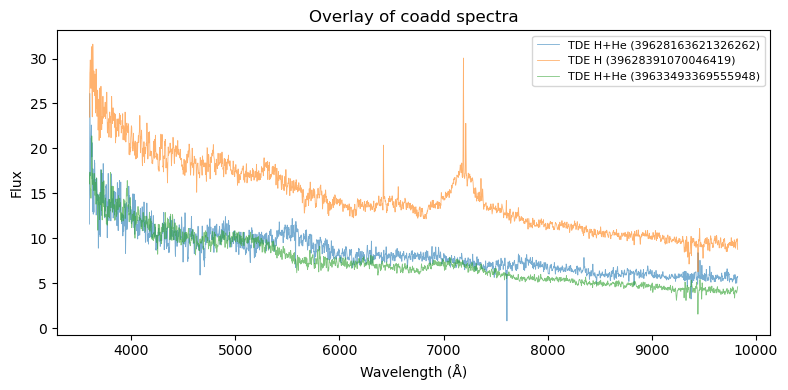

In [21]:
import matplotlib.pyplot as plt
import numpy as np

def plot_overlay_flux(coadds, n_show=10, smooth=False):
    plt.figure(figsize=(8,4))
    for rec in coadds[:n_show]:
        w, f, iv = np.asarray(rec["wave"]), np.asarray(rec["flux"]), np.asarray(rec["ivar"])
        if iv is not None:
            m = iv > 0
            w, f = w[m], f[m]
        if smooth:
            from scipy.ndimage import gaussian_filter1d
            f = gaussian_filter1d(f, 2.0)
        plt.plot(w, f, lw=0.6, alpha=0.6, label=f"{rec['type']} ({rec['TARGETID']})")
    plt.xlabel("Wavelength (Å)")
    plt.ylabel("Flux")
    plt.title("Overlay of coadd spectra")
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


plot_overlay_flux(coadds_old, n_show=3, smooth=True)
#plot_overlay_flux(coadds_new, n_show=8, smooth=True)

In [23]:
import numpy as np

# Combine and deduplicate by TARGETID
def merge_coadds(coadds_old, coadds_new):
    all_coadds = {rec["TARGETID"]: rec for rec in coadds_old if rec is not None}
    for rec in coadds_new:
        if rec is None: 
            continue
        tid = rec.get("TARGETID")
        if tid is not None:
            all_coadds[tid] = rec  # new overwrites old if duplicate
    return list(all_coadds.values())

coadds_merged = merge_coadds(coadds_old, coadds_new)
print(f"Merged total: {len(coadds_merged)} spectra")


NameError: name 'coadds_new' is not defined

In [ ]:
OUT_NPZ = "/global/cfs/cdirs/m4237/zixinq/data/transient_coadd_fluxes_classified.npz"

np.savez_compressed(
    OUT_NPZ,
    TARGETID=np.array([r["TARGETID"] for r in coadds_merged], dtype=np.int64),
    NIGHT=np.array([r.get("NIGHT", -1) for r in coadds_merged], dtype=np.int64),
    TILEID=np.array([r.get("tileid", -1) for r in coadds_merged], dtype=np.int32),
    Z=np.array([r.get("z", np.nan) for r in coadds_merged], dtype=float),
    Z_NGSF=np.array([r.get("z_ngsf", np.nan) for r in coadds_merged], dtype=float),
    CLASS_NGSF=np.array([r.get("class_ngsf", None) for r in coadds_merged], dtype=object),
    wave=np.array([r["wave"] for r in coadds_merged], dtype=object),
    flux=np.array([r["flux"] for r in coadds_merged], dtype=object),
    ivar=np.array([r["ivar"] for r in coadds_merged], dtype=object),
    path=np.array([r.get("path", None) for r in coadds_merged], dtype=object),
    allow_pickle=True
)

print(f"Saved merged coadds to {OUT_NPZ}")


In [24]:
OUT_NPZ = "/global/cfs/cdirs/m4237/zixinq/data/new/transient_coadd_fluxes_classified.npz"

coadds_merged = coadds_old

np.savez_compressed(
    OUT_NPZ,
    TARGETID=np.array([r["TARGETID"] for r in coadds_merged], dtype=np.int64),
    NIGHT=np.array([r.get("NIGHT", -1) for r in coadds_merged], dtype=np.int64),
    TILEID=np.array([r.get("tileid", -1) for r in coadds_merged], dtype=np.int32),
    Z=np.array([r.get("z", np.nan) for r in coadds_merged], dtype=float),
    TYPE=np.array([r.get("type", None) for r in coadds_merged], dtype=object),
    wave=np.array([r["wave"] for r in coadds_merged], dtype=object),
    flux=np.array([r["flux"] for r in coadds_merged], dtype=object),
    ivar=np.array([r["ivar"] for r in coadds_merged], dtype=object),
    path=np.array([r.get("path", None) for r in coadds_merged], dtype=object),
    allow_pickle=True
)

print(f"Saved merged coadds to {OUT_NPZ}")

Saved merged coadds to /global/cfs/cdirs/m4237/zixinq/data/new/transient_coadd_fluxes_classified.npz


In [17]:
#get spectra for new datset
from multiprocessing import Pool
from tqdm import tqdm
from astropy.table import Table

#classified_new = Table.from_pandas(classified_new)

with Pool(16) as pool:
    results = list(tqdm(pool.imap(process_transient, classified_new), total=len(classified_new)))

  0%|          | 0/197 [00:00<?, ?it/s]

Error processing TARGETID None: 'str' object has no attribute 'colnames'Error processing TARGETID None: 'str' object has no attribute 'colnames'Error processing TARGETID None: 'str' object has no attribute 'colnames'Error processing TARGETID None: 'str' object has no attribute 'colnames'Error processing TARGETID None: 'str' object has no attribute 'colnames'Error processing TARGETID None: 'str' object has no attribute 'colnames'Error processing TARGETID None: 'str' object has no attribute 'colnames'Error processing TARGETID None: 'str' object has no attribute 'colnames'Error processing TARGETID None: 'str' object has no attribute 'colnames'
Error processing TARGETID None: 'str' object has no attribute 'colnames'Error processing TARGETID None: 'str' object has no attribute 'colnames'









Error processing TARGETID None: 'str' object has no attribute 'colnames'
Error processing TARGETID None: 'str' object has no attribute 'colnames'


  7%|▋         | 13/197 [00:00<00:00, 260.87it/s]


In [30]:
out_npz = "/global/cfs/cdirs/m4237/zixinq/data/new/transient_coadd_fluxes_classified.npz"
save_flattened_results(results, out_npz)

Saved (per-camera + coadd) to: /global/cfs/cdirs/m4237/zixinq/data/new/transient_coadd_fluxes_classified.npz


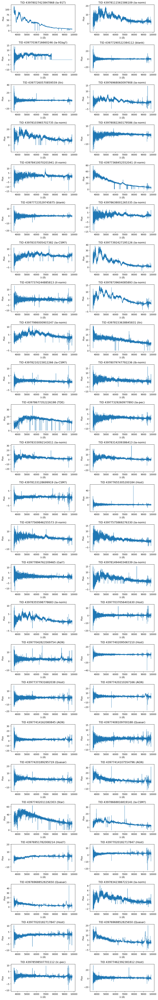

In [31]:
import matplotlib.pyplot as plt
N = 50
ncols = 2
nrows = int(np.ceil(N / ncols))
valid = [r for r in results if r is not None]

fig, axes = plt.subplots(nrows, ncols, figsize=(10, nrows*2.5))

for i, res in enumerate(valid[:N]):
    ax = axes.flat[i]
    wave = np.asarray(res["coadd"]["wave"])
    flux = np.asarray(res["coadd"]["flux"])
    ax.plot(wave, flux, lw=0.8)
    ax.set_title(f"TID {res['TARGETID']} ({res['TYPE']})")
    ax.set_xlabel("λ (Å)")
    ax.set_ylabel("Flux")

plt.tight_layout()
plt.show()


In [118]:
from multiprocessing import Pool
from tqdm import tqdm


with Pool(16) as pool:
    results = list(tqdm(pool.imap(process_transient, transient_catalog), total=len(transient_catalog)))

out_npz = "/global/cfs/cdirs/m4237/zixinq/data/transient_coadd_fluxes.npz"
save_flattened_results(results, out_npz)

  0%|          | 0/3184 [00:00<?, ?it/s]

INFO:spectra.py:453:read_spectra: iotime 0.604 sec to read spectra from:  coadd-5-26164-thru20241210.fits at 2025-10-14T11:52:07.928388
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.104 [sec]
INFO:spectra.py:453:read_spectra: iotime 0.592 sec to read spectra from:  coadd-5-27827-thru20250331.fits at 2025-10-14T11:52:08.149089
INFO:spectra.py:453:read_spectra: iotime 0.562 sec to read spectra from:  coadd-5-24930-thru20230523.fits at 2025-10-14T11:52:08.219459
INFO:spectra.py:453:read_spectra: iotime 0.848 sec to read spectra from:  coadd-0-24698-thru20220307.fits at 2025-10-14T11:52:08.257340
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.110 [sec]
INFO:spectra.py:453:read_spectra: iotime 0.886 sec to read spectra from:  coadd-2-3752-thru20250430.fits at 2025-10-14T11:52:08.299242
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.123 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectr

  0%|          | 1/3184 [00:05<4:55:43,  5.57s/it]

INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.114 [sec]
INFO:spectra.py:453:read_spectra: iotime 1.294 sec to read spectra from:  coadd-8-1873-thru20250728.fits at 2025-10-14T11:52:12.739473
INFO:spectra.py:453:read_spectra: iotime 1.692 sec to read spectra from:  coadd-2-26292-thru20250517.fits at 2025-10-14T11:52:12.830882
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.103 [sec]
INFO:spectra.py:453:read_spectra: iotime 1.812 sec to read spectra from:  coadd-2-10206-thru20211112.fits at 2025-10-14T11:52:12.906507
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.115 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.100 [sec]
INFO:spectra.py:453:read_spectra: iotime 1.227 sec to read spectra from:  coadd-4-4068-thru20220127.fits at 2025-10-14T11:52:13.105895
INFO:spectra.py:453:read_spectra: iotime 2.322 sec to read spectra from:  coadd-5-9374-thru20230826.fi

  1%|          | 37/3184 [00:08<10:22,  5.05it/s] 

...

INFO:spectra.py:453:read_spectra: iotime 4.819 sec to read spectra from:  coadd-7-42873-thru20211218.fits at 2025-10-14T11:57:35.374601
INFO:spectra.py:453:read_spectra: iotime 4.498 sec to read spectra from:  coadd-4-41705-thru20230830.fits at 2025-10-14T11:57:35.376454
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.100 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.099 [sec]


100%|█████████▉| 3180/3184 [05:28<00:00,  8.89it/s]

INFO:spectra.py:453:read_spectra: iotime 4.861 sec to read spectra from:  coadd-6-40734-thru20241112.fits at 2025-10-14T11:57:35.609024
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.099 [sec]
INFO:spectra.py:453:read_spectra: iotime 4.993 sec to read spectra from:  coadd-1-42810-thru20240105.fits at 2025-10-14T11:57:35.847154
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.101 [sec]


100%|██████████| 3184/3184 [05:28<00:00,  9.68it/s]


Saved (per-camera + coadd) to: /global/cfs/cdirs/m4237/zixinq/data/transient_coadd_fluxes.npz


In [121]:
import numpy as np
import pandas as pd
import os

NPZ_IN  = "/global/cfs/cdirs/m4237/zixinq/data/transient_coadd_fluxes.npz"     # file or .npz
CSV_IN  = "/global/cfs/cdirs/m4237/zixinq/data/transient_catalog.csv"
NPZ_OUT = "/global/cfs/cdirs/m4237/zixinq/data/transient_coadd_fluxes.npz"

def augment_npz_with_Z_from_csv(npz_in, csv_in, npz_out,
                                id_col_npz="TARGETID", id_col_csv="TARGETID",
                                z_col_csv="Z", out_z_col="Z"):
    # normalize paths/extensions
    if not npz_in.endswith(".npz"):  npz_in  = npz_in + ".npz"
    if not csv_in.endswith(".csv"):  csv_in  = csv_in + ".csv"

    # 1) load NPZ
    data = np.load(npz_in, allow_pickle=True)
    if id_col_npz not in data:
        raise ValueError(f"{id_col_npz} not found in {npz_in}")
    tids = np.array(data[id_col_npz]).astype(np.int64)

    # 2) load CSV and build map TARGETID -> Z
    df = pd.read_csv(csv_in)
    if id_col_csv not in df.columns:
        raise ValueError(f"{id_col_csv} not found in {csv_in}")
    if z_col_csv not in df.columns:
        raise ValueError(f"{z_col_csv} not found in {csv_in}")

    df[id_col_csv] = pd.to_numeric(df[id_col_csv], errors="coerce").astype("Int64")
    df[z_col_csv]  = pd.to_numeric(df[z_col_csv],  errors="coerce")  # float

    z_map = dict(zip(df[id_col_csv].dropna().astype(int), df[z_col_csv]))

    # 3) create output dict (copy all original fields)
    out = {k: data[k] for k in data.files}

    # 4) align Z to NPZ order
    z_aligned = np.full(len(tids), np.nan, dtype=np.float64)
    matched = 0
    for i, tid in enumerate(tids):
        v = z_map.get(int(tid), np.nan)
        if pd.notna(v):
            z_aligned[i] = float(v)
            matched += 1
    out[out_z_col] = z_aligned
    out["ONE_PLUS_Z"] = (1.0 + z_aligned).astype(np.float64)

    # 5) save and report
    np.savez_compressed(npz_out, **out)
    print(f"Saved: {npz_out}")
    print(f"Total spectra: {len(tids)} | Z matches: {matched} ({matched/len(tids):.1%})")

In [122]:
# run it
augment_npz_with_Z_from_csv(NPZ_IN, CSV_IN, NPZ_OUT)

Saved: /global/cfs/cdirs/m4237/zixinq/data/transient_coadd_fluxes.npz
Total spectra: 2870 | Z matches: 2870 (100.0%)


In [123]:
GLOBAL_OUT = "/global/cfs/cdirs/m4237/zixinq/data/transient_coadd_fluxes.npz"
co = np.load(GLOBAL_OUT,  allow_pickle=True)
my_pandas_series = pd.Series(co['TYPE'])
value_counts_result = my_pandas_series.value_counts()

In [124]:
value_counts_result

SN Ia      2013
SN II       439
SN Ib/c     180
Unknown      76
TDE          73
AGN          57
Host         25
QSO           7
Name: count, dtype: int64

In [8]:
#save flux data for classified transietns
from multiprocessing import Pool
with Pool(16) as pool:
    results = list(tqdm(pool.imap(process_spectrum, transient_catalog), total=len(transient_catalog)))

  0%|          | 4/29115 [00:01<3:34:19,  2.26it/s]

INFO:spectra.py:451:read_spectra: iotime 2.366 sec to read spectra from:  spectra-2-4803-thru20230906.fits.gz at 2025-07-24T19:27:42.187591


  0%|          | 5/29115 [00:04<10:26:58,  1.29s/it]

INFO:spectra.py:451:read_spectra: iotime 2.187 sec to read spectra from:  spectra-3-2449-thru20221219.fits.gz at 2025-07-24T19:27:42.471358


  0%|          | 6/29115 [00:04<7:40:29,  1.05it/s] 

...

100%|█████████▉| 29113/29115 [3:30:06<00:00,  2.44it/s]

INFO:spectra.py:451:read_spectra: iotime 2.592 sec to read spectra from:  spectra-3-42064-thru20250706.fits.gz at 2025-07-24T22:57:44.786430


100%|█████████▉| 29114/29115 [3:30:07<00:00,  2.30it/s]

INFO:spectra.py:451:read_spectra: iotime 2.532 sec to read spectra from:  spectra-4-42064-thru20250706.fits.gz at 2025-07-24T22:57:45.115249


100%|██████████| 29115/29115 [3:30:07<00:00,  2.31it/s]


In [ ]:
#save flux data for classified transietns
from multiprocessing import Pool
with Pool(16) as pool:
    results = list(tqdm(pool.imap(process_spectrum, transient_catalog), total=len(transient_catalog)))

In [9]:
import numpy as np
import numpy.ma as ma

grouped_fluxes = {
    "b": {},
    "r": {},
    "z": {}
}

for r in results:
    if r is None:
        continue

    raw_type = r.get("type", "UNKNOWN")
    if ma.is_masked(raw_type) or raw_type is None:
        label = "UNKNOWN"
    else:
        label = str(raw_type).strip()

    # Clean up label
    if "?" in label:
        continue
    elif "Ib" in label or "Ic" in label:
        label = "SN Ib/c"
    elif "Ia" in label:
        label = "SN Ia"
    elif "II" in label:
        label = "SN II"
    elif label.lower() == "galaxy":
        label = "GALAXY"

    for band in ["b", "r", "z"]:
        try:
            flux = r["spectra"][band]["flux"]
            grouped_fluxes[band].setdefault(label, []).append(flux)
        except KeyError:
            print(f"Missing {band}-band flux for label {label}")

In [10]:
output_path = "/global/cfs/cdirs/m4237/zixinq/data/transient_fluxes.npz"

flattened = {
    "TARGETID": [],
    "NIGHT": [],
    "TYPE": [],
    "b_flux": [],
    "b_wave": [],
    "b_ivar": [],
    "r_flux": [],
    "r_wave": [],
    "r_ivar": [],
    "z_flux": [],
    "z_wave": [],
    "z_ivar": [],
}

for entry in results:
    if entry is None:
        continue

    spec = entry["spectra"]
    flattened["TARGETID"].append(entry["TARGETID"])
    flattened["NIGHT"].append(entry["NIGHT"])
    flattened["TYPE"].append(entry.get("simplified_type", "Unknown"))

    for band in ["b", "r", "z"]:
        if band in spec:
            flattened[f"{band}_flux"].append(spec[band]["flux"])
            flattened[f"{band}_wave"].append(spec[band]["wave"])
            flattened[f"{band}_ivar"].append(spec[band]["ivar"])
        else:
            flattened[f"{band}_flux"].append(np.array([]))
            flattened[f"{band}_wave"].append(np.array([]))
            flattened[f"{band}_ivar"].append(np.array([]))

np.savez_compressed(output_path, **flattened)
print(f"Saved all classified fluxes to: {output_path}")


Saved all classified fluxes to: /global/cfs/cdirs/m4237/zixinq/data/transient_fluxes.npz


In [20]:
from collections import Counter

def simplify_label(label):
    label = str(label).strip().lower()
    if "?" in label:
        return None
    elif "ib" in label or "ic" in label:
        return "SN Ib/c"
    elif "iip" in label or "iil" in label or "ii" in label:
        return "SN II"
    elif "ia" in label:
        return "SN Ia"
    elif "tde" in label:
        return "TDE"
    elif "agn" in label:
        return "AGN"
    elif "qso" in label or "quasar" in label:
        return "QSO"
    elif "gal" in label or "host" in label:
        return "Host"
    else:
        return "Unknown"
type_counts = Counter()

for r in results:
    if r is None:
        continue
    raw_type = r.get("type", None)
    label = simplify_label(raw_type)
    if label:
        type_counts[label] += 1

In [21]:
for label, count in type_counts.most_common():
    print(f"{label}: {count}")

Unknown: 186


In [13]:
output_dir = "/global/cfs/cdirs/m4237/zixinq/plots"
os.makedirs(output_dir, exist_ok=True)

plot_path = os.path.join(output_dir, "classified_transient_flux_grid.png")

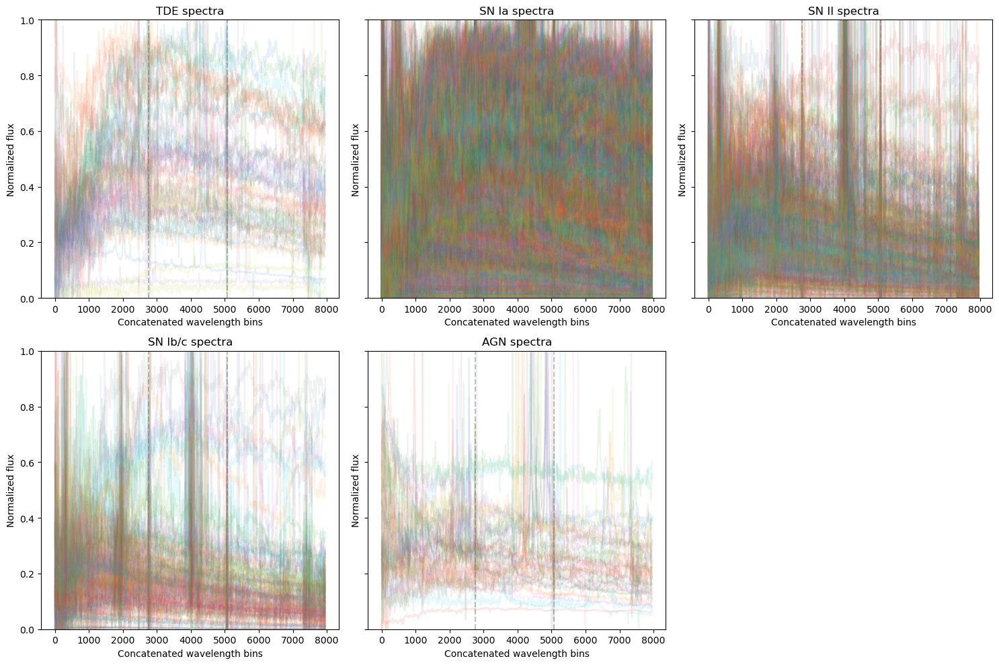

Saved plot to: /global/cfs/cdirs/m4237/zixinq/plots/classified_transient_flux_grid.png


In [14]:
import numpy as np
import matplotlib.pyplot as plt

plot_order = ["TDE", "SN Ia", "SN II", "SN Ib/c", "AGN"]
plot_order = [t for t in plot_order if t in grouped_fluxes["r"]] 

n_cols = 3
n_rows = (len(plot_order) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows), sharex=False, sharey=True)
axes = axes.flatten()

for i, key in enumerate(plot_order):
    ax = axes[i]
    fluxes_b = grouped_fluxes["b"].get(key, [])
    fluxes_r = grouped_fluxes["r"].get(key, [])
    fluxes_z = grouped_fluxes["z"].get(key, [])

    min_count = min(len(fluxes_b), len(fluxes_r), len(fluxes_z))
    for j in range(min_count):
        try:
            full_flux = np.concatenate([
                fluxes_b[j],
                fluxes_r[j],
                fluxes_z[j]
            ])
            if np.nanmax(full_flux) > 0:
                norm_flux = full_flux / np.nanmax(full_flux)
                ax.plot(norm_flux, alpha=0.1)
        except Exception as e:
            print(f"Skipping {key} sample {j}: {e}")

    len_b = len(fluxes_b[0]) if fluxes_b else 0
    len_r = len(fluxes_r[0]) if fluxes_r else 0
    ax.axvline(len_b, color="gray", linestyle="--", alpha=0.5)
    ax.axvline(len_b + len_r, color="gray", linestyle="--", alpha=0.5)

    ax.set_ylim(0, 1)
    ax.set_title(f"{key} spectra")
    ax.set_xlabel("Concatenated wavelength bins")
    ax.set_ylabel("Normalized flux")

for j in range(len(plot_order), len(axes)):
    axes[j].axis('off')


plt.tight_layout()
plt.savefig(plot_path, dpi=300)  
plt.show()
print(f"Saved plot to: {plot_path}")

In [15]:
def save_plots_to_pdf(figures, filename):
    with PdfPages(filename) as pdf:
        for fig in figures:
            if fig:
                pdf.savefig(fig)
                plt.close(fig)

In [16]:
types = ["Gal", "AGN", "Ia", "Ib", "Ic", "II", "TDE"]
limits = {
    "Gal": [-np.inf, np.inf], "AGN": [-np.inf, np.inf],
    "Ia": [-1, 100], "Ib": [-1, 100], "Ic": [-1, 100],
    "II": [-1, 100], "TDE": [-1, np.inf]
}

csv_path = "/global/cfs/cdirs/m4237/zixinq/data/matched_classified_transients.csv"
transient_catalog = Table.from_pandas(pd.read_csv(csv_path))
TNS_match_DESI = transient_catalog
TNS_match_DESI["TILEID"] = TNS_match_DESI["TILEID"].astype(int)
TNS_match_DESI["NIGHT"] = TNS_match_DESI["NIGHT_x"].astype(int)
TNS_match_DESI["PETAL_LOC"] = TNS_match_DESI["PETAL_LOC"].astype(int)

In [22]:
def process_spectrum(row, output_dir="/global/cfs/cdirs/m4237/zixinq/data/spectra"):
    try:
        path = build_spectrum_path(row)
        if not os.path.exists(path):
            print(f"Missing file: {path}")
            return None

        spectra = read_spectra(path, targetids=int(row["TARGETID"]))
        spectra = coadd_cameras(spectra)

        wave = spectra.wave["brz"]
        flux = spectra.flux["brz"][0]
        ivar = spectra.ivar["brz"][0]

        smoothed_flux = gaussian_filter1d(flux, 5)
        std = np.sqrt(np.where(ivar > 0, 1.0 / ivar, np.nan))
        smoothed_std = gaussian_filter1d(std, 5)
        smoothed_std_clean = np.nan_to_num(smoothed_std, nan=0.0, posinf=0.0, neginf=0.0)

        # Save CSV
        os.makedirs(output_dir, exist_ok=True)
        spectrum_table = Table({
            'wavelength': wave,
            'flux': smoothed_flux,
            'fluxerr': smoothed_std_clean
        })
        csv_path = os.path.join(output_dir, f"{int(row['TARGETID'])}.csv")
        spectrum_table.to_pandas().to_csv(csv_path, index=False)

        # Plot and save PNG
        plt.figure(figsize=(10, 4))
        plt.plot(wave, smoothed_flux, label="Flux", lw=1)
        plt.fill_between(wave, smoothed_flux - smoothed_std_clean, smoothed_flux + smoothed_std_clean,
                         color="gray", alpha=0.3, label="Flux Error")
        plt.title(f"Spectrum for TARGETID {int(row['TARGETID'])} (Type: {row.get('TYPE', 'N/A')})")
        plt.xlabel("Wavelength (Å)")
        plt.ylabel("Flux")
        plt.legend()
        plt.tight_layout()

        plot_path = os.path.join(output_dir, f"{int(row['TARGETID'])}.png")
        plt.savefig(plot_path)
        plt.close()

        return {
            "wavelength": wave,
            "flux": smoothed_flux,
            "fluxerr": smoothed_std_clean,
            "targetid": int(row["TARGETID"]),
            "type": row["TYPE"],
            "z": row.get("Z_x", None),
        }

    except Exception as e:
        print(f"Error processing TARGETID {row.get('TARGETID', 'UNKNOWN')}: {e}")
        return None

In [ ]:
from multiprocessing import Pool
with Pool(16) as pool:
    results = list(tqdm(pool.imap(process_spectrum, transient_catalog), total=len(transient_catalog)))

In [ ]:
for r in results:
    if r:
        plt.figure(figsize=(12, 6))
        plt.plot(r['wavelength'], r['flux'], label='Flux')
        plt.fill_between(r['wavelength'], r['flux'] - r['fluxerr'], r['flux'] + r['fluxerr'], alpha=0.3)
        plt.title(f"TID {r['targetid']} ({r['type']}), z={r['z']}")
        plt.xlabel("Wavelength [Å]")
        plt.ylabel("Flux")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

flux_dict = {
    "Galaxy": galaxy_flux,
    "SN Ia": snia_flux,
    "SN Ib": snib_flux,
    "SN Ib/c": snibc_flux,
    "SN Ic": snic_flux,
    "SN IIn": sniin_flux,
    "SN IILP": sniilp_flux,
    "SN IIP": sniip_flux,
    "SN IIpec": sniipec_flux,
    "Kilonova": kn_flux
}

N = 5

for class_name, flux_array in flux_dict.items():
    plt.figure(figsize=(10, 4))
    for i in range(min(N, len(flux_array))):
        flux = flux_array[i]
        plt.plot(np.linspace(3600, 9824, len(flux)), flux, alpha=0.7, label=f'Example {i+1}')
    plt.title(f"{class_name} — {min(N, len(flux_array))} Example Spectra")
    plt.xlabel("Wavelength [Å]")
    plt.ylabel("Rescaled Flux")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [2]:
import numpy as np
import pandas as pd

# Load your classified table and the NPZ file
classified_all = pd.read_csv("classified_all.csv")  # or however you load it
coadd = np.load("/global/cfs/cdirs/m4237/zixinq/data/transient_coadd_fluxes.npz", allow_pickle=True)

# The NPZ should have arrays like:
# 'targetid', 'flux', 'wave', 'ivar', etc.
print(coadd.files)

# Extract the relevant arrays
targetid_all = coadd["TARGETID"]
flux_all = coadd["coadd_flux"]
ivar_all = coadd.get("coadd_ivar", None)
wave = coadd["coadd_wave"]
TYPE = coadd["TYPE"]
Z = coadd["Z"]

# --- Create mask for classified targets ---
classified_targets = classified_all["TARGETID"].fillna(0).astype(np.int64).values
mask = np.isin(targetid_all, classified_targets)

# --- Subset ---
flux_subset = flux_all[mask]
targetid_subset = targetid_all[mask]
if ivar_all is not None:
    ivar_subset = ivar_all[mask]

print(f"Selected {flux_subset.shape[0]} out of {flux_all.shape[0]} spectra.")

# --- Save subset ---
out_path = "/global/cfs/cdirs/m4237/zixinq/data/transient_coadd_fluxes_classified.npz"
if ivar_all is not None:
    np.savez_compressed(out_path, targetid=targetid_subset, flux=flux_subset, ivar=ivar_subset, wave=wave, TYPE = TYPE, Z = Z)
else:
    np.savez_compressed(out_path, targetid=targetid_subset, flux=flux_subset, wave=wave, TYPE = TYPE, Z = Z)

print("Saved subset to:", out_path)


['TARGETID', 'NIGHT', 'TYPE', 'Z', 'b_flux', 'b_wave', 'b_ivar', 'r_flux', 'r_wave', 'r_ivar', 'z_flux', 'z_wave', 'z_ivar', 'coadd_flux', 'coadd_wave', 'coadd_ivar', 'coadd_band', 'ONE_PLUS_Z']
Selected 15 out of 2870 spectra.
Saved subset to: /global/cfs/cdirs/m4237/zixinq/data/transient_coadd_fluxes_classified.npz


In [3]:
classified_all.head()

,TARGETID,NIGHT,RA,DEC,TYPE,Z,obsdate,discoverydate
0,3.962816e+16,20230226.0,167.498983,15.756843,TDE,0.184867,2023-02-26,2023-01-13 10:56:38
1,3.962839e+16,20220610.0,262.460454,25.842183,TDE,0.095387,2022-06-10,2022-03-20 14:41:18
2,3.963349e+16,20220113.0,104.623680,70.560788,TDE,0.080989,2022-01-13,2022-01-21 7:17:46
3,3.963324e+16,20220318.0,185.187735,49.551283,TDE,0.028436,2022-03-18,2022-02-22 14:52:48
4,3.963298e+16,20210416.0,252.530615,34.818831,TDE,0.357822,2021-04-16,2021-03-18 11:44:34


In [ ]:
import numpy as np
from astropy.io import fits
import pandas as pd
import requests
from io import BytesIO

def load_fafn_spectrum(fafn_entry):
    """
    fafn_entry: value from the FAFN column (may be NaN, '', URL, or local path)
    Returns (wave, flux, ivar) or None if cannot read.
    """
    # 1) Handle missing
    if pd.isna(fafn_entry):
        return None

    fafn = str(fafn_entry).strip()
    if not fafn:
        return None

    hdul = fits.open(fafn)

    # 4) Extract wavelength / flux / ivar from a typical 1D spectrum FITS
    #    (you may need to adapt column names depending on the archive)
    hdu = hdul[1] if len(hdul) > 1 else hdul[0]
    data = hdu.data
    cols = [c.upper() for c in data.columns.names]

    # Try to guess column names:
    if "WAVELENGTH" in cols:
        wave = data["WAVELENGTH"]
    elif "LAMBDA" in cols:
        wave = data["LAMBDA"]
    elif "WAVE" in cols:
        wave = data["WAVE"]
    else:
        # fallback: pixel index if nothing better
        wave = np.arange(len(data))

    if "FLUX" in cols:
        flux = data["FLUX"]
    else:
        # fallback to first column if you know it’s flux-like
        flux = data.field(0)

    if "IVAR" in cols:
        ivar = data["IVAR"]
    elif "ERR" in cols or "ERROR" in cols:
        # if you only have sigma, convert to ivar
        err_col = "ERR" if "ERR" in cols else "ERROR"
        sigma = data[err_col]
        with np.errstate(divide="ignore", invalid="ignore"):
            ivar = np.where(sigma > 0, 1.0 / sigma**2, 0.0)
    else:
        ivar = None

    hdul.close()
    return wave, flux, ivar


In [1]:
# 1) Install once (e.g. in a Jupyter/conda env)
!pip install sparclclient

# 2) Use the client
from sparcl.client import SparclClient

targetid = 39628163621326262

client = SparclClient()

spectra = client.retrieve_by_specid(
    [targetid],  # can be a list of many TARGETIDs
    include=['wavelength', 'flux', 'ivar', 'model', 'wave_sigma']
)

spec = spectra.records[0]

wave = spec.wavelength   # 1D array of wavelengths (Angstrom)
flux = spec.flux         # 1D array of flux (same length as wave)
ivar = spec.ivar         # 1D array of inverse variance
model = spec.model       # Best-fit model spectrum
sigma = spec.wave_sigma  # LSF width per pixel (if you need it)


Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-1.26.3-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
Using cached numpy-1.26.3-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.2 MB)
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
scipy 1.8.1 requires numpy<1.25.0,>=1.17.3, but you have numpy 1.26.3 which is incompatible.
torchvision 0.23.0 requires torch==2.8.0, but you have torch 2.2.2+cpu which is incompatible.
umap-learn 0.5.9.post2 requires scikit-learn>=1.6, but you have scikit-learn 1.4.2 which is incompatible.


IndexError: list index out of range

In [ ]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(wave, flux, label="data")
plt.plot(wave, model, label="model", alpha=0.7)
plt.xlabel("Wavelength [Å]")
plt.ylabel("Flux")
plt.legend()
plt.show()
